# ABSA Indodax — FASE 4: Prediksi Korpus dan Output BAB IV

**Versi V5.4.3 — Checkpoint-aware corpus inference**

Notebook ini **tidak melakukan training ulang**. Fase 4 hanya memuat artefak Fase 1–3, mengevaluasi kembali model pada test set, menjalankan inferensi seluruh korpus, dan menyusun paket output BAB IV.

## Quick Start

1. Simpan folder proyek pada Google Drive:

   ```text
   MyDrive/
   └── ABSA_Indodax_Pipeline_V5_4_4Fase/
       ├── 01_data_preparation/
       ├── 02_annotation_processing/
       └── 03_model_training_evaluation/
   ```

2. **ZIP checkpoint tidak wajib** apabila ketiga folder tersebut masih lengkap. Notebook akan selalu memakai folder terlebih dahulu.
3. Fase 4 final mewajibkan provenance `manual_human`, `final_research_run=true`, dan Fase 3 `V5.4.2_FASE3_FELIA_STYLE_ROBUST_SAFE`.
4. Buka **Runtime → Change runtime type → T4 GPU**.
5. Pada cell konfigurasi, biarkan:
   - `STORAGE_MODE = "drive"`
   - `RESET_STAGE4_OUTPUT = False`
   - `REUSE_COMPLETE_PREDICTIONS = True`
   - `CLEAR_INFERENCE_CACHE = False`
6. Jalankan **Runtime → Run all**.
7. Beri izin Google Drive saat diminta.
8. Pastikan tabel **PRE-FLIGHT CHECK** menunjukkan seluruh file `OK`.
9. Jika session terputus, jalankan ulang dari awal. Inferensi akan melanjutkan cache chunk terakhir, bukan mengulang dari nol.
10. Paket akhir tersimpan sebagai:

   ```text
   MyDrive/ABSA_Indodax_Pipeline_V5_4_4Fase/
   └── stage4_bab4_results_v5_4_3_final_robust_fingerprint.zip
   ```

## Perlindungan yang ditambahkan

- Tidak ada fallback diam-diam ke `/content`; path Google Drive harus valid.
- Folder Fase 1–3 diprioritaskan, sehingga ZIP rusak tidak akan dibuka jika folder sudah lengkap.
- ZIP hanya digunakan bila folder tidak lengkap, dan diperiksa dengan `is_zipfile()` serta `testzip()`.
- File model `.pt` diperiksa sebelum GPU digunakan.
- Inferensi korpus dilakukan per chunk dan disimpan secara atomik.
- Hasil prediksi lengkap dapat digunakan ulang.
- Cache disimpan di luar folder output sehingga tidak hilang ketika output dibersihkan.
- File eksperimen Fase 3 otomatis disalin ke output Fase 4.
- ZIP hasil akhir diverifikasi sebelum dipindahkan ke Google Drive.
- Visualisasi tetap menggunakan gaya Felia: gradasi biru, tabel report, dan 300 DPI.


Tambahan: FP32 default; cache dan hasil lengkap terikat fingerprint model, dataset, konfigurasi, dan label.


In [ ]:
# =========================================================
# 0. INSTALL LIBRARY — KOMPATIBEL DENGAN RUNTIME COLAB
# =========================================================
# scikit-learn tidak diturunkan secara paksa agar tidak bentrok dengan
# paket bawaan Colab seperti umap-learn dan hdbscan.

%pip -q install --upgrade-strategy only-if-needed \
    "transformers>=4.44,<5" \
    "accelerate>=0.34,<2" \
    "wordcloud>=1.9.3,<2" \
    "openpyxl>=3.1.5,<4" \
    "xlsxwriter>=3.2,<4" \
    "seaborn>=0.13.2,<1"


In [ ]:
# =========================================================
# 1. IMPORT, DRIVE, SEED, DAN KONFIGURASI UTAMA
# =========================================================

import os
import re
import gc
import json
import math
import time
import random
import shutil
import hashlib
import warnings
import zipfile
import tempfile
from pathlib import Path
from collections import Counter, defaultdict
from contextlib import nullcontext
from datetime import datetime

# ---------------------------------------------------------
# KONFIGURASI YANG BOLEH DIUBAH
# ---------------------------------------------------------
STORAGE_MODE = "drive"  # gunakan "drive" untuk Google Colab
PROJECT_NAME = "ABSA_Indodax_Pipeline_V5_4_4Fase"

# False adalah pilihan paling aman untuk rerun dan resume.
RESET_STAGE4_OUTPUT = False

# Cache inferensi berada di luar folder output.
CLEAR_INFERENCE_CACHE = False

# Gunakan hasil lengkap yang sudah pernah terbentuk.
REUSE_COMPLETE_PREDICTIONS = True

# Jika proses terputus, lanjutkan dari chunk terakhir.
RESUME_CHUNK_PREDICTIONS = True
INFERENCE_CHUNK_SIZE = 2000

# Mixed precision mempercepat inferensi GPU dan menghemat memori.
USE_MIXED_PRECISION = False
REQUIRE_GPU = True

# Final research guard. Jangan diubah untuk skripsi final.
REQUIRE_MANUAL_HUMAN = True
REQUIRE_FINAL_RESEARCH_RUN = True
REQUIRED_STAGE3_PIPELINE = "V5.4.2_FASE3_FELIA_STYLE_ROBUST_SAFE"

# Debug opsional. Biarkan False untuk hasil penelitian.
DEBUG_FAST_RUN = False
DEBUG_N_ROWS = 300

# ---------------------------------------------------------
# GOOGLE DRIVE — TIDAK ADA FALLBACK DIAM-DIAM
# ---------------------------------------------------------
if STORAGE_MODE != "drive":
    raise ValueError(
        "Notebook V5.4.3 dikonfigurasi untuk Google Drive. "
        "Ubah STORAGE_MODE hanya jika seluruh path disesuaikan."
    )

try:
    from google.colab import drive
except ImportError as exc:
    raise RuntimeError(
        "Notebook ini harus dijalankan di Google Colab agar dapat "
        "mengakses Google Drive."
    ) from exc

drive.mount("/content/drive", force_remount=False)

DRIVE_ROOT = Path("/content/drive/MyDrive")
if not DRIVE_ROOT.exists():
    raise FileNotFoundError(
        f"Google Drive tidak berhasil dimount: {DRIVE_ROOT}"
    )

PROJECT_DIR = DRIVE_ROOT / PROJECT_NAME
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

# Folder sumber. Notebook tidak membuat folder Fase 1–3 secara otomatis,
# agar folder kosong tidak disalahartikan sebagai checkpoint lengkap.
DRIVE_STAGE1_DIR = PROJECT_DIR / "01_data_preparation"
DRIVE_STAGE2_DIR = PROJECT_DIR / "02_annotation_processing"
DRIVE_STAGE3_DIR = PROJECT_DIR / "03_model_training_evaluation"

STAGE4_DIR = PROJECT_DIR / "04_corpus_analysis_bab4"
CACHE_DIR = PROJECT_DIR / "_fase4_inference_cache"
RESTORE_ROOT = Path("/content/absa_checkpoint_restore")

if RESET_STAGE4_OUTPUT and STAGE4_DIR.exists():
    shutil.rmtree(STAGE4_DIR)

if CLEAR_INFERENCE_CACHE and CACHE_DIR.exists():
    shutil.rmtree(CACHE_DIR)

STAGE4_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
RESTORE_ROOT.mkdir(parents=True, exist_ok=True)

OUT_DIR = STAGE4_DIR
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Cache Hugging Face disimpan di Drive agar tidak perlu mengunduh ulang
# model dasar pada session Colab berikutnya.
HF_CACHE_DIR = PROJECT_DIR / "_huggingface_cache"
HF_CACHE_DIR.mkdir(parents=True, exist_ok=True)
os.environ["HF_HOME"] = str(HF_CACHE_DIR)
os.environ["TRANSFORMERS_CACHE"] = str(HF_CACHE_DIR)
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# ---------------------------------------------------------
# IMPORT LIBRARY SETELAH CACHE DAN DRIVE SIAP
# ---------------------------------------------------------
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

import sklearn
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings("ignore")


def set_global_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception as exc:
        print("Peringatan determinisme:", exc)


set_global_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if REQUIRE_GPU and DEVICE.type != "cuda":
    raise RuntimeError(
        "GPU belum aktif. Buka Runtime → Change runtime type → T4 GPU, "
        "kemudian jalankan notebook dari awal."
    )

if DEVICE.type == "cuda":
    torch.set_float32_matmul_precision("high")

print("Device       :", DEVICE)
if DEVICE.type == "cuda":
    print("GPU          :", torch.cuda.get_device_name(0))
print("PROJECT_DIR  :", PROJECT_DIR)
print("OUT_DIR      :", OUT_DIR)
print("CACHE_DIR    :", CACHE_DIR)
print("HF_CACHE_DIR :", HF_CACHE_DIR)

# -----------------------------
# Gaya visual BAB IV — Felia Style
# -----------------------------
FIGURE_DPI = 300
FELIA_BLUE_CMAP = "Blues"
FELIA_HEADER_BLUE = "#1F4E78"
FELIA_LIGHT_BLUE = "#EEF4FA"
FELIA_BAR_BLUE = "#4C78A8"
FELIA_BAR_BLUE_LIGHT = "#9ECAE1"

SENTIMENT_COLORS = {
    "negatif": "#E74C3C",
    "netral": "#3498DB",
    "positif": "#2ECC71",
}
ASPECT_COLORS = {
    "antarmuka_pengguna": "#4C78A8",
    "keamanan": "#72B7B2",
    "transaksi": "#F2CF5B",
    "layanan_pelanggan": "#F58518",
    "tidak_relevan": "#9D9D9D",
}

sns.set_theme(
    context="notebook",
    style="whitegrid",
    font_scale=1.0,
)
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": FIGURE_DPI,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.frameon": False,
})

RAW_DATA_PATH = "indodax_reviews.xlsx"

# -----------------------------
# Label penelitian
# -----------------------------
# Empat aspek berikut adalah aspek substantif yang dianalisis.
RESEARCH_ASPECT_LABELS = [
    "antarmuka_pengguna",
    "keamanan",
    "transaksi",
    "layanan_pelanggan",
]

# tidak_relevan dipakai sebagai kelas operasional model aspek untuk mencegah
# seluruh ulasan umum dipaksa masuk ke salah satu dari empat aspek penelitian.
IRRELEVANT_ASPECT_LABEL = "tidak_relevan"
ASPECT_MODEL_LABELS = RESEARCH_ASPECT_LABELS + [IRRELEVANT_ASPECT_LABEL]

# Alias kompatibilitas untuk fungsi lama: sekarang berisi lima kelas model aspek.
ASPECT_LABELS = ASPECT_MODEL_LABELS
ANNOTATION_ASPECT_LABELS = ASPECT_MODEL_LABELS
ASPECT_LABELING_POLICY = "single_dominant_aspect"

SENTIMENT_LABELS = ["negatif", "netral", "positif"]

ASPECT_DISPLAY_LABELS = {
    "antarmuka_pengguna": "Antarmuka pengguna / UI-UX",
    "keamanan": "Keamanan akun dan transaksi",
    "transaksi": "Transaksi, termasuk biaya, deposit, withdraw, pajak, order, dan jual-beli",
    "layanan_pelanggan": "Layanan pelanggan / customer service",
    "tidak_relevan": "Tidak relevan / tidak membahas empat aspek penelitian",
}

ASPECT_DEFINITIONS = {
    "antarmuka_pengguna": "Tampilan, kemudahan penggunaan, navigasi, performa aplikasi, bug, crash, loading, update, dan pengalaman penggunaan.",
    "keamanan": "Keamanan akun, login, OTP, KYC, verifikasi, autentikasi, privasi, pembobolan, dan perlindungan dana.",
    "transaksi": "Deposit, withdraw, transfer, fee/biaya, pajak, saldo, order beli/jual, pending, gagal transaksi, dan kecepatan transaksi.",
    "layanan_pelanggan": "Customer service, admin, bantuan, komplain, tiket, email, respons, dan penyelesaian masalah.",
    "tidak_relevan": "Ulasan umum atau ulasan yang tidak membahas satu pun dari empat aspek penelitian. Kelas ini menjadi relevance gate pada model aspek dan tidak ikut analisis sentimen per aspek.",
}

SENTIMENT_DEFINITIONS = {
    "negatif": "Keluhan, kekecewaan, kritik, masalah, pengalaman buruk, atau ketidakpuasan.",
    "netral": "Informasi deskriptif, pertanyaan, pernyataan tanpa emosi kuat, atau polaritas tidak jelas.",
    "positif": "Pujian, kepuasan, rekomendasi, apresiasi, atau pengalaman baik.",
}

ASPECT_ALIASES = {
    "antarmuka_pengguna": "antarmuka_pengguna",
    "antarmuka": "antarmuka_pengguna",
    "ui": "antarmuka_pengguna",
    "ux": "antarmuka_pengguna",
    "user_interface": "antarmuka_pengguna",
    "pengalaman_pengguna": "antarmuka_pengguna",
    "tampilan": "antarmuka_pengguna",
    "keamanan": "keamanan",
    "security": "keamanan",
    "aman": "keamanan",
    "verifikasi": "keamanan",
    "kyc": "keamanan",
    "otp": "keamanan",
    "login": "keamanan",
    "transaksi": "transaksi",
    "biaya_transaksi": "transaksi",
    "biaya": "transaksi",
    "fee": "transaksi",
    "pajak": "transaksi",
    "withdraw": "transaksi",
    "withdrawal": "transaksi",
    "wd": "transaksi",
    "deposit": "transaksi",
    "depo": "transaksi",
    "transfer": "transaksi",
    "saldo": "transaksi",
    "order": "transaksi",
    "jual_beli": "transaksi",
    "jual beli": "transaksi",
    "transaction": "transaksi",
    "layanan_pelanggan": "layanan_pelanggan",
    "layanan": "layanan_pelanggan",
    "customer_service": "layanan_pelanggan",
    "customer service": "layanan_pelanggan",
    "cs": "layanan_pelanggan",
    "support": "layanan_pelanggan",
    "bantuan": "layanan_pelanggan",
    "tidak_relevan": "tidak_relevan",
    "tidak relevan": "tidak_relevan",
    "umum": "tidak_relevan",
    "lainnya": "tidak_relevan",
    "di_luar_aspek": "tidak_relevan",
    "di luar aspek": "tidak_relevan",
}

SENTIMENT_ALIASES = {
    "negatif": "negatif",
    "negative": "negatif",
    "minus": "negatif",
    "buruk": "negatif",
    "jelek": "negatif",
    "netral": "netral",
    "neutral": "netral",
    "biasa": "netral",
    "informasi": "netral",
    "positif": "positif",
    "positive": "positif",
    "plus": "positif",
    "baik": "positif",
    "bagus": "positif",
}

# -----------------------------
# Sampling, split, near-duplicate, dan balancing
# -----------------------------
TOTAL_REVIEW_TARGET = 80000
LABELED_SAMPLE_SIZE = 8000

TRAIN_RATIO = 0.60
VAL_RATIO = 0.20
TEST_RATIO = 0.20
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-9

USE_RATING_FOR_SAMPLING_DIVERSITY = True
ANNOTATION_TEMPLATE_INCLUDE_RATING = False

GROUP_SPLIT_N_FOLDS = 5
NEAR_DUP_SIMILARITY_THRESHOLD = 0.92
NEAR_DUP_N_NEIGHBORS = 5
NEAR_DUP_MAX_FEATURES = 30000

# Dua dataset latih dibuat terpisah:
# 1) model aspek: oversampling berdasarkan kelas aspek;
# 2) model sentimen: hanya data relevan dan oversampling berdasarkan joint aspect-sentiment.
ASPECT_ROS_TARGET_MIN = 300
ASPECT_ROS_TARGET_MAX = 600
SENTIMENT_JOINT_ROS_TARGET_MIN = 100
SENTIMENT_JOINT_ROS_TARGET_MAX = 150

MIN_CLASS_COUNT_FOR_STRATIFY = 5
LOW_SUPPORT_THRESHOLD = 30

# -----------------------------
# Model dan early stopping
# -----------------------------
MODEL_NAME = "indobenchmark/indobert-base-p1"
FREEZE_BERT = False
MODEL_SELECTION_METRIC = "val_macro_f1"
EARLY_STOPPING_PATIENCE = 2
EARLY_STOPPING_MIN_DELTA = 0.002

TUNING_CONFIGS = [
    {
        "config_name": "layer2_h128_do035_lr2e-5_len160_ep5",
        "max_len": 160,
        "batch_size": 8,
        "learning_rate": 2e-5,
        "dropout": 0.35,
        "lstm_hidden": 128,
        "lstm_layers": 2,
        "epochs": 5,
    },
    {
        "config_name": "layer3_h128_do035_lr2e-5_len160_ep5",
        "max_len": 160,
        "batch_size": 8,
        "learning_rate": 2e-5,
        "dropout": 0.35,
        "lstm_hidden": 128,
        "lstm_layers": 3,
        "epochs": 5,
    },
    {
        "config_name": "layer4_h128_do035_lr2e-5_len160_ep5",
        "max_len": 160,
        "batch_size": 8,
        "learning_rate": 2e-5,
        "dropout": 0.35,
        "lstm_hidden": 128,
        "lstm_layers": 4,
        "epochs": 5,
    },
]


library_versions = {
    "python": os.sys.version,
    "torch": torch.__version__,
    "transformers": __import__("transformers").__version__,
    "sklearn": sklearn.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
}

run_config = {
    "pipeline_version": "V5.4.3_FINAL_ROBUST_FINGERPRINT_FELIA_STYLE",
    "timestamp": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "seed": SEED,
    "library_versions": library_versions,
    "raw_data_path": RAW_DATA_PATH,
    "total_review_target": TOTAL_REVIEW_TARGET,
    "labeled_sample_size": LABELED_SAMPLE_SIZE,
    "research_aspect_labels": RESEARCH_ASPECT_LABELS,
    "aspect_model_labels": ASPECT_MODEL_LABELS,
    "irrelevant_aspect_label": IRRELEVANT_ASPECT_LABEL,
    "sentiment_labels": SENTIMENT_LABELS,
    "aspect_labeling_policy": ASPECT_LABELING_POLICY,
    "split_strategy": "StratifiedGroupKFold_5fold_near_duplicate_group",
    "near_duplicate_similarity_threshold": NEAR_DUP_SIMILARITY_THRESHOLD,
    "train_ratio": TRAIN_RATIO,
    "validation_ratio": VAL_RATIO,
    "test_ratio": TEST_RATIO,
    "aspect_ros_target_range": [ASPECT_ROS_TARGET_MIN, ASPECT_ROS_TARGET_MAX],
    "sentiment_joint_ros_target_range": [
        SENTIMENT_JOINT_ROS_TARGET_MIN,
        SENTIMENT_JOINT_ROS_TARGET_MAX,
    ],
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "early_stopping_min_delta": EARLY_STOPPING_MIN_DELTA,
    "low_support_threshold": LOW_SUPPORT_THRESHOLD,
    "model_name": MODEL_NAME,
    "freeze_bert": FREEZE_BERT,
    "model_selection_metric": MODEL_SELECTION_METRIC,
    "require_manual_human": REQUIRE_MANUAL_HUMAN,
    "require_final_research_run": REQUIRE_FINAL_RESEARCH_RUN,
    "required_stage3_pipeline": REQUIRED_STAGE3_PIPELINE,
    "tuning_configs": TUNING_CONFIGS,
}
if "ANNOTATION_PROVENANCE" in globals():
    run_config["annotation_provenance"] = ANNOTATION_PROVENANCE

with open(OUT_DIR / "00_run_config.json", "w", encoding="utf-8") as file:
    json.dump(run_config, file, indent=2, ensure_ascii=False)

with open(OUT_DIR / "00_library_versions.json", "w", encoding="utf-8") as file:
    json.dump(library_versions, file, indent=2, ensure_ascii=False)

print("Konfigurasi tersimpan:", OUT_DIR / "00_run_config.json")


## Perbaikan metodologis dan teknis

Notebook mempertahankan desain penelitian V5.4:

- model aspek lima kelas dengan `tidak_relevan` sebagai *relevance gate*;
- model sentimen hanya untuk empat aspek substantif;
- evaluasi aspect, sentiment dengan gold aspect, sentiment pipeline, dan Joint ABSA 13 kelas;
- label *Majority Voting* dipertahankan pada data yang telah dianotasi;
- model hanya digunakan untuk data korpus yang belum dianotasi;
- evaluasi per aspek dan audit kelas dengan support kecil;
- visualisasi BAB IV bergaya Felia.

Tambahan V5.4.2:

- pre-flight check sebelum model dimuat;
- folder checkpoint diprioritaskan daripada ZIP;
- ZIP rusak dilewati dan tidak menyebabkan `BadZipFile`;
- tidak ada fallback path yang membuat notebook membaca `/content` secara keliru;
- cache inferensi per chunk;
- penggunaan ulang hasil prediksi lengkap;
- ZIP output akhir diuji integritasnya.


- run final default FP32;
- cache lama otomatis ditolak bila model/data/config berbeda.


In [ ]:
# =========================================================
# 2. FUNGSI BANTU UMUM
# =========================================================

def save_df(df, filename, index=False):
    path = OUT_DIR / filename
    df.to_excel(path, index=index)
    print("Saved:", path)
    return path


def save_json(obj, filename):
    path = OUT_DIR / filename
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False)
    print("Saved:", path)
    return path


def normalize_label_text(value):
    """Normalisasi teks label agar variasi spasi, huruf besar, dan tanda hubung lebih aman."""
    if pd.isna(value):
        return np.nan
    text = str(value).strip().lower()
    if text in ["", "nan", "none", "null", "-", "_"]:
        return np.nan
    text = re.sub(r"[\s\-/]+", "_", text)
    text = re.sub(r"_+", "_", text).strip("_")
    return text if text else np.nan


def canonicalize_aspect_label(value):
    """Memetakan variasi label aspek ke label resmi penelitian."""
    label = normalize_label_text(value)
    if pd.isna(label):
        return np.nan
    label = ASPECT_ALIASES.get(label, label)
    return label if label in ANNOTATION_ASPECT_LABELS else np.nan


def canonicalize_sentiment_label(value):
    """Memetakan variasi label sentimen ke label resmi penelitian."""
    label = normalize_label_text(value)
    if pd.isna(label):
        return np.nan
    label = SENTIMENT_ALIASES.get(label, label)
    return label if label in SENTIMENT_LABELS else np.nan


def display_label_guide():
    """Menampilkan panduan label yang konsisten dengan proposal dan notebook."""
    aspect_guide = pd.DataFrame([
        {"aspect_label": k, "display_name": ASPECT_DISPLAY_LABELS[k], "definition": ASPECT_DEFINITIONS[k]}
        for k in ANNOTATION_ASPECT_LABELS
    ])
    sentiment_guide = pd.DataFrame([
        {"sentiment_label": k, "definition": SENTIMENT_DEFINITIONS[k]}
        for k in SENTIMENT_LABELS
    ])
    display(aspect_guide)
    display(sentiment_guide)
    return aspect_guide, sentiment_guide



def pretty_label(label):
    mapping = {
        "antarmuka_pengguna": "Antarmuka Pengguna",
        "keamanan": "Keamanan",
        "transaksi": "Transaksi",
        "layanan_pelanggan": "Layanan Pelanggan",
        "tidak_relevan": "Tidak Relevan",
        "negatif": "Negatif",
        "netral": "Netral",
        "positif": "Positif",
        "accuracy": "Accuracy",
        "macro avg": "Macro Average",
        "weighted avg": "Weighted Average",
    }
    text = str(label)
    if text in mapping:
        return mapping[text]
    if "__" in text:
        aspect, sentiment = text.split("__", 1)
        return (
            f"{mapping.get(aspect, aspect.replace('_', ' ').title())} - "
            f"{mapping.get(sentiment, sentiment.title())}"
        )
    return text.replace("_", " ").title()


def save_figure(fig, filename, folder=None):
    target_dir = FIG_DIR if folder is None else Path(folder)
    target_dir.mkdir(parents=True, exist_ok=True)
    path = target_dir / filename
    fig.savefig(
        path,
        dpi=FIGURE_DPI,
        bbox_inches="tight",
        facecolor="white",
    )
    plt.show()
    plt.close(fig)
    print("Saved figure:", path)
    return path


def add_bar_value_labels(axis, decimals=0):
    for container in axis.containers:
        labels = []
        for value in container.datavalues:
            if pd.isna(value):
                labels.append("")
            elif decimals == 0:
                labels.append(f"{int(round(value))}")
            else:
                labels.append(f"{value:.{decimals}f}")
        axis.bar_label(
            container,
            labels=labels,
            padding=3,
            fontsize=8.5,
            fontweight="bold",
        )


def plot_count_series(
    series,
    title,
    xlabel,
    ylabel,
    filename,
    rotation=30,
    colors=None,
):
    data = series.copy()
    labels = [pretty_label(value) for value in data.index]

    if isinstance(colors, dict):
        bar_colors = [
            colors.get(value, FELIA_BAR_BLUE)
            for value in data.index
        ]
    elif colors is None:
        bar_colors = FELIA_BAR_BLUE
    else:
        bar_colors = colors

    fig, axis = plt.subplots(figsize=(9, 5))
    axis.bar(labels, data.values, color=bar_colors)
    axis.set_title(title)
    axis.set_xlabel(xlabel)
    axis.set_ylabel(ylabel)
    axis.tick_params(axis="x", rotation=rotation)
    for tick in axis.get_xticklabels():
        tick.set_ha("right" if rotation else "center")
    axis.grid(axis="y", alpha=0.25)
    add_bar_value_labels(axis)
    fig.tight_layout()
    return save_figure(fig, filename)


def plot_heatmap_table(
    table,
    title,
    filename,
    xlabel="Sentimen",
    ylabel="Aspek",
):
    data = (
        table.copy()
        .apply(pd.to_numeric, errors="coerce")
        .fillna(0)
    )

    fig, axis = plt.subplots(figsize=(8, 5))
    sns.heatmap(
        data,
        annot=True,
        fmt=".0f",
        cmap=FELIA_BLUE_CMAP,
        linewidths=0.5,
        linecolor="white",
        cbar_kws={"label": "Jumlah Data"},
        ax=axis,
    )
    axis.set_title(title)
    axis.set_xlabel(xlabel)
    axis.set_ylabel(ylabel)
    axis.set_xticklabels(
        [pretty_label(value) for value in data.columns],
        rotation=0,
    )
    axis.set_yticklabels(
        [pretty_label(value) for value in data.index],
        rotation=0,
    )
    fig.tight_layout()
    return save_figure(fig, filename)


def plot_confusion_matrix(cm, labels, title, filename):
    label_count = len(labels)
    if label_count <= 5:
        figsize = (7.5, 6)
        rotation = 25
        annotation_size = 10
    else:
        figsize = (13, 10)
        rotation = 55
        annotation_size = 7

    fig, axis = plt.subplots(figsize=figsize)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap=FELIA_BLUE_CMAP,
        linewidths=0.5,
        linecolor="white",
        square=label_count <= 5,
        cbar=True,
        annot_kws={"fontsize": annotation_size},
        ax=axis,
    )
    axis.set_title(title)
    axis.set_xlabel("Label Prediksi")
    axis.set_ylabel("Label Aktual")
    axis.set_xticklabels(
        [pretty_label(label) for label in labels],
        rotation=rotation,
        ha="right",
    )
    axis.set_yticklabels(
        [pretty_label(label) for label in labels],
        rotation=0,
    )
    fig.tight_layout()
    return save_figure(fig, filename)


def plot_learning_curve(history_df, title_prefix, filename_prefix):
    if history_df.empty:
        return

    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    metrics = [
        ("train_loss", "val_loss", "Loss"),
        ("train_acc", "val_acc", "Accuracy"),
        ("train_macro_f1", "val_macro_f1", "Macro F1"),
    ]

    for axis, (train_col, val_col, y_label) in zip(axes, metrics):
        if train_col not in history_df.columns or val_col not in history_df.columns:
            axis.axis("off")
            continue

        axis.plot(
            history_df["epoch"],
            history_df[train_col],
            marker="o",
            label="Training",
        )
        axis.plot(
            history_df["epoch"],
            history_df[val_col],
            marker="o",
            label="Validation",
        )
        axis.set_title(y_label)
        axis.set_xlabel("Epoch")
        axis.set_ylabel(y_label)
        axis.grid(alpha=0.25)
        axis.legend()

        if y_label in {"Accuracy", "Macro F1"}:
            axis.set_ylim(0, 1.05)

    fig.suptitle(f"Kurva Training {title_prefix}", fontweight="bold")
    fig.tight_layout()
    return save_figure(
        fig,
        f"{filename_prefix}_dashboard.png",
    )


def fleiss_kappa(label_matrix, categories):
    """Menghitung Fleiss' Kappa untuk beberapa annotator.

    Parameters
    ----------
    label_matrix : list[list[str]]
        Setiap baris berisi label dari seluruh annotator untuk satu objek.
        Fungsi ini mengharuskan jumlah annotator sama pada setiap baris dan
        seluruh label termasuk dalam ``categories``.
    categories : list[str]
        Seluruh kategori yang mungkin pada proses anotasi.
    """
    if not label_matrix:
        return np.nan

    rows = []
    expected_raters = None
    for row_idx, labels in enumerate(label_matrix):
        if expected_raters is None:
            expected_raters = len(labels)
        if len(labels) != expected_raters:
            raise ValueError(
                f"Jumlah annotator tidak konsisten pada baris {row_idx}: "
                f"expected={expected_raters}, got={len(labels)}"
            )
        unknown = [label for label in labels if label not in categories]
        if unknown:
            raise ValueError(
                f"Label di luar kategori pada baris {row_idx}: {unknown}. "
                f"Kategori resmi: {categories}"
            )
        rows.append([labels.count(cat) for cat in categories])

    M = np.asarray(rows, dtype=float)
    if M.size == 0:
        return np.nan

    row_totals = M.sum(axis=1)
    if not np.allclose(row_totals, row_totals[0]):
        raise ValueError("Jumlah penilaian per objek tidak konsisten.")

    N = M.shape[0]
    n = float(row_totals[0])
    if n <= 1:
        return np.nan

    agreement_per_item = ((M ** 2).sum(axis=1) - n) / (n * (n - 1))
    observed_agreement = agreement_per_item.mean()
    category_proportions = M.sum(axis=0) / (N * n)
    expected_agreement = (category_proportions ** 2).sum()

    if abs(1 - expected_agreement) < 1e-12:
        return np.nan
    return (observed_agreement - expected_agreement) / (1 - expected_agreement)


def majority_vote(labels):
    c = Counter([x for x in labels if pd.notna(x)])
    if not c:
        return np.nan
    top = c.most_common()
    # Jika voting seri, tidak dipakai agar label final lebih aman.
    if len(top) > 1 and top[0][1] == top[1][1]:
        return np.nan
    return top[0][0]


In [ ]:
# =========================================================
# 2A. SANITY CHECK FUNGSI WAJIB
# =========================================================

required_functions = [
    "save_df",
    "plot_count_series",
    "plot_heatmap_table",
    "plot_confusion_matrix",
    "plot_learning_curve",
    "fleiss_kappa",
    "majority_vote",
]

missing_required_functions = [fn for fn in required_functions if fn not in globals() or not callable(globals()[fn])]
if missing_required_functions:
    raise NameError(f"Fungsi wajib belum tersedia: {missing_required_functions}")

print("Sanity check fungsi wajib: OK")


## Fungsi preprocessing untuk dokumentasi BAB IV

Fungsi berikut hanya didefinisikan ulang agar contoh tabel preprocessing pada output BAB IV dapat dibuat.
Data bersih tidak dihitung ulang; `clean_df` dimuat langsung dari checkpoint Bagian 1.


In [ ]:
# =========================================================
# 4. PREPROCESSING TEKS — LIGHT PREPROCESSING BERBASIS DOMAIN
# =========================================================
# Istilah domain penting seperti login, fee, withdraw, deposit, OTP, KYC,
# wallet, dan spread dipertahankan agar sinyal aspek tidak hilang.

PHRASE_NORMALIZATION = {
    "log in": "login",
    "customer servis": "customer service",
    "costumer service": "customer service",
    "customer care": "customer service",
}

SLANG_DICT = {
    "gak": "tidak",
    "ga": "tidak",
    "nggak": "tidak",
    "ngga": "tidak",
    "tdk": "tidak",
    "tak": "tidak",
    "gk": "tidak",
    "bgt": "banget",
    "bgtt": "banget",
    "bangett": "banget",
    "apk": "aplikasi",
    "app": "aplikasi",
    "apps": "aplikasi",
    "cs": "customer service",
    "cust": "customer",
    "tx": "transaksi",
    "wd": "withdraw",
    "wede": "withdraw",
    "depo": "deposit",
    "tf": "transfer",
    "eror": "error",
    "errorr": "error",
    "lemottt": "lemot",
    "lelet": "lambat",
    "mantul": "mantap",
}


def normalize_slang(text):
    text = str(text)
    for source, target in PHRASE_NORMALIZATION.items():
        text = re.sub(
            rf"(?<!\w){re.escape(source)}(?!\w)",
            target,
            text,
            flags=re.IGNORECASE,
        )
    tokens = text.split()
    return " ".join(SLANG_DICT.get(token, token) for token in tokens)


def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"@[A-Za-z0-9_]+", " ", text)
    text = re.sub(r"#[A-Za-z0-9_]+", " ", text)
    text = re.sub(r"[^a-zA-ZÀ-ÿ0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    text = normalize_slang(text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


# Fungsi di atas hanya dipakai untuk dokumentasi contoh preprocessing BAB IV.


In [ ]:
# =========================================================
# 7. PRE-FLIGHT DAN LOAD CHECKPOINT FASE 1–3
# =========================================================

STAGE1_REQUIRED = [
    "01_standardized_reviews.xlsx",
    "02_clean_reviews.xlsx",
]

STAGE2_REQUIRED = [
    "06_final_majority_labels.xlsx",
    "06_fleiss_kappa.xlsx",
    "06_labeling_quality_report.xlsx",
    "06_annotation_provenance.json",
    "06_joint_label_table.xlsx",
    "07_split_info_before_oversampling.xlsx",
    "07_oversampling_info_train.xlsx",
    "07_train_raw.xlsx",
    "07_train_aspect_oversampled.xlsx",
    "07_train_sentiment_oversampled.xlsx",
    "07_validation.xlsx",
    "07_test.xlsx",
    "07A_aspect_distribution_before_after_oversampling.xlsx",
    "07A_joint_label_distribution_before_after_oversampling.xlsx",
    "07_near_duplicate_group_audit.xlsx",
    "07_group_split_overlap_audit.xlsx",
]

STAGE3_REQUIRED = [
    "00_run_config.json",
    "06_annotation_provenance.json",
    "models/aspect_indobert_bilstm_5class.pt",
    "models/sentiment_indobert_bilstm_relevant.pt",
    "08_aspect_training_history_all.xlsx",
    "08_aspect_tuning_results.xlsx",
    "09_sentiment_training_history_all.xlsx",
    "09_sentiment_tuning_results.xlsx",
    "08_aspect_best_config.json",
    "09_sentiment_best_config.json",
]


def missing_relative_files(root_dir, required_files):
    return [
        relative_path
        for relative_path in required_files
        if not (root_dir / relative_path).is_file()
    ]


def locate_stage_root(extract_root, required_files):
    first_required = Path(required_files[0])
    matches = list(extract_root.rglob(first_required.name))

    for match in matches:
        if len(first_required.parts) == 1:
            candidate_root = match.parent
        else:
            candidate_root = match.parents[len(first_required.parts) - 1]

        if not missing_relative_files(candidate_root, required_files):
            return candidate_root

    return None


def inspect_zip(zip_path):
    if not zip_path.exists():
        return False, "tidak ditemukan"

    if not zipfile.is_zipfile(zip_path):
        return False, "bukan ZIP valid"

    try:
        with zipfile.ZipFile(zip_path, "r") as archive:
            bad_member = archive.testzip()
        if bad_member is not None:
            return False, f"anggota rusak: {bad_member}"
    except (zipfile.BadZipFile, OSError) as exc:
        return False, f"gagal dibaca: {exc}"

    return True, "valid"


def find_valid_checkpoint_zip(zip_names):
    search_directories = [
        PROJECT_DIR,
        Path("/content"),
        Path.cwd(),
        Path("/mnt/data"),
    ]

    checked_rows = []
    seen = set()

    for zip_name in zip_names:
        for directory in search_directories:
            candidate = directory / zip_name
            candidate_key = str(candidate.resolve()) if candidate.exists() else str(candidate)

            if candidate_key in seen:
                continue
            seen.add(candidate_key)

            if not candidate.exists():
                continue

            valid, reason = inspect_zip(candidate)
            checked_rows.append({
                "path": str(candidate),
                "valid": valid,
                "reason": reason,
            })

            if valid:
                return candidate, pd.DataFrame(checked_rows)

    return None, pd.DataFrame(checked_rows)


def resolve_stage_directory(
    stage_name,
    preferred_dir,
    required_files,
    zip_names,
):
    missing = missing_relative_files(preferred_dir, required_files)

    if not missing:
        print(f"{stage_name}: menggunakan folder Google Drive")
        print("→", preferred_dir)
        return preferred_dir

    print(f"{stage_name}: folder belum lengkap.")
    print("File hilang:", missing)

    valid_zip, zip_audit = find_valid_checkpoint_zip(zip_names)
    if not zip_audit.empty:
        display(zip_audit)

    if valid_zip is None:
        raise FileNotFoundError(
            f"{stage_name} belum lengkap di {preferred_dir}. "
            f"Tidak ditemukan ZIP valid dari: {zip_names}. "
            "ZIP tidak diperlukan apabila folder tahap tersebut masih lengkap."
        )

    restore_dir = RESTORE_ROOT / stage_name.lower().replace(" ", "_")
    if restore_dir.exists():
        shutil.rmtree(restore_dir)
    restore_dir.mkdir(parents=True, exist_ok=True)

    print(f"Mengekstrak ZIP valid: {valid_zip}")
    with zipfile.ZipFile(valid_zip, "r") as archive:
        archive.extractall(restore_dir)

    resolved_root = locate_stage_root(restore_dir, required_files)
    if resolved_root is None:
        raise FileNotFoundError(
            f"ZIP {valid_zip} berhasil diekstrak, tetapi struktur "
            f"{stage_name} tidak memuat semua file wajib."
        )

    print(f"{stage_name}: menggunakan hasil restore lokal")
    print("→", resolved_root)
    return resolved_root


STAGE1_DIR = resolve_stage_directory(
    "Fase 1",
    DRIVE_STAGE1_DIR,
    STAGE1_REQUIRED,
    ["stage1_checkpoint.zip"],
)

STAGE2_DIR = resolve_stage_directory(
    "Fase 2",
    DRIVE_STAGE2_DIR,
    STAGE2_REQUIRED,
    ["stage2_checkpoint_v5_4.zip", "stage2_checkpoint.zip"],
)

STAGE3_DIR = resolve_stage_directory(
    "Fase 3",
    DRIVE_STAGE3_DIR,
    STAGE3_REQUIRED,
    [
        "stage3_checkpoint_v5_4.zip",
        "stage3_model_results_v5_4.zip",
        "stage3_model_results_v5_3.zip",
    ],
)

# ---------------------------------------------------------
# PRE-FLIGHT REPORT
# ---------------------------------------------------------
preflight_rows = []

for stage_name, stage_dir, required_files in [
    ("Fase 1", STAGE1_DIR, STAGE1_REQUIRED),
    ("Fase 2", STAGE2_DIR, STAGE2_REQUIRED),
    ("Fase 3", STAGE3_DIR, STAGE3_REQUIRED),
]:
    for relative_path in required_files:
        path = stage_dir / relative_path
        preflight_rows.append({
            "stage": stage_name,
            "relative_path": relative_path,
            "resolved_path": str(path),
            "status": "OK" if path.is_file() else "MISSING",
            "size_mb": (
                round(path.stat().st_size / (1024 ** 2), 3)
                if path.is_file()
                else np.nan
            ),
        })

preflight_df = pd.DataFrame(preflight_rows)
display(preflight_df)

if (preflight_df["status"] != "OK").any():
    raise FileNotFoundError(
        "Pre-flight gagal. Masih ada file checkpoint yang hilang."
    )

# Model berukuran ratusan MB. Pemeriksaan ini mencegah file kosong/korup.
for model_relative_path in [
    "models/aspect_indobert_bilstm_5class.pt",
    "models/sentiment_indobert_bilstm_relevant.pt",
]:
    model_path = STAGE3_DIR / model_relative_path
    if model_path.stat().st_size < 50 * 1024 * 1024:
        raise RuntimeError(
            f"Ukuran model tidak wajar: {model_path}. "
            "Kemungkinan file tidak lengkap."
        )

free_local_gb = shutil.disk_usage("/content").free / (1024 ** 3)
print(f"Ruang kosong lokal: {free_local_gb:.2f} GB")
if free_local_gb < 3:
    raise RuntimeError(
        "Ruang kosong /content kurang dari 3 GB. "
        "Hapus file sementara sebelum melanjutkan."
    )

save_df(preflight_df, "00_input_preflight.xlsx")
print("PRE-FLIGHT CHECK: SEMUA FILE WAJIB OK")

# ---------------------------------------------------------
# LOAD DATA FASE 1 DAN 2
# ---------------------------------------------------------
work_df = pd.read_excel(STAGE1_DIR / "01_standardized_reviews.xlsx")
clean_df = pd.read_excel(STAGE1_DIR / "02_clean_reviews.xlsx")

labeled_df = pd.read_excel(STAGE2_DIR / "06_final_majority_labels.xlsx")
kappa_df = pd.read_excel(STAGE2_DIR / "06_fleiss_kappa.xlsx")
labeling_quality_df = pd.read_excel(
    STAGE2_DIR / "06_labeling_quality_report.xlsx"
)

with open(
    STAGE2_DIR / "06_annotation_provenance.json",
    "r",
    encoding="utf-8",
) as file:
    annotation_provenance_info = json.load(file)

# ---------------------------------------------------------
# FINAL RESEARCH LINEAGE GUARD — FASE 2 + FASE 3
# ---------------------------------------------------------
with open(
    STAGE3_DIR / "00_run_config.json",
    "r",
    encoding="utf-8",
) as file:
    stage3_run_config = json.load(file)

with open(
    STAGE3_DIR / "06_annotation_provenance.json",
    "r",
    encoding="utf-8",
) as file:
    stage3_provenance_info = json.load(file)

if REQUIRE_MANUAL_HUMAN:
    if annotation_provenance_info.get("annotation_provenance") != "manual_human":
        raise RuntimeError(
            "STOP: Fase 4 wajib memakai Fase 2 manual_human. "
            f"Ditemukan: {annotation_provenance_info.get('annotation_provenance')}"
        )
    if stage3_provenance_info.get("annotation_provenance") != "manual_human":
        raise RuntimeError(
            "STOP: Fase 3 bukan manual_human. "
            f"Ditemukan: {stage3_provenance_info.get('annotation_provenance')}"
        )
    if stage3_run_config.get("annotation_provenance") != "manual_human":
        raise RuntimeError(
            "STOP: 00_run_config Fase 3 tidak mencatat manual_human."
        )

if REQUIRE_FINAL_RESEARCH_RUN:
    if annotation_provenance_info.get("final_research_run") is not True:
        raise RuntimeError("STOP: Fase 2 bukan final_research_run.")
    if stage3_provenance_info.get("final_research_run") is not True:
        raise RuntimeError("STOP: provenance Fase 3 bukan final_research_run.")
    if stage3_run_config.get("final_research_run") is not True:
        raise RuntimeError("STOP: run_config Fase 3 bukan final_research_run.")

if stage3_run_config.get("pipeline_version") != REQUIRED_STAGE3_PIPELINE:
    raise RuntimeError(
        "STOP: pipeline Fase 3 tidak sesuai final baseline. "
        f"Expected={REQUIRED_STAGE3_PIPELINE}, "
        f"found={stage3_run_config.get('pipeline_version')}"
    )

if stage3_run_config.get("source_stage2_pipeline") != "V5.4.1_FASE2_FIX_KAPPA_ROBUST":
    raise RuntimeError(
        "STOP: lineage Fase 3 tidak menunjuk Fase 2 final yang diharapkan."
    )

print("✅ FINAL RESEARCH LINEAGE VALID")
print("   Fase 2 provenance  : manual_human / final=True")
print("   Fase 3 provenance  : manual_human / final=True")
print("   Fase 3 pipeline    :", stage3_run_config.get("pipeline_version"))

# Update run_config Fase 4 setelah lineage benar-benar diketahui.
run_config["annotation_provenance"] = annotation_provenance_info["annotation_provenance"]
run_config["final_research_run"] = annotation_provenance_info["final_research_run"]
run_config["source_stage2_pipeline"] = stage3_run_config.get("source_stage2_pipeline")
run_config["source_stage3_pipeline"] = stage3_run_config.get("pipeline_version")
run_config["source_stage3_timestamp"] = stage3_run_config.get("timestamp")
run_config["source_stage3_provenance"] = stage3_run_config.get("annotation_provenance")

with open(OUT_DIR / "00_run_config.json", "w", encoding="utf-8") as file:
    json.dump(run_config, file, indent=2, ensure_ascii=False)

source_lineage = {
    "stage2_provenance": annotation_provenance_info,
    "stage3_provenance": stage3_provenance_info,
    "stage3_run_config": stage3_run_config,
}
with open(OUT_DIR / "00_source_lineage.json", "w", encoding="utf-8") as file:
    json.dump(source_lineage, file, indent=2, ensure_ascii=False)

joint_table_file = pd.read_excel(STAGE2_DIR / "06_joint_label_table.xlsx")
joint_table = (
    joint_table_file
    .set_index("aspect")
    .reindex(
        index=RESEARCH_ASPECT_LABELS,
        columns=SENTIMENT_LABELS,
        fill_value=0,
    )
)

split_info = pd.read_excel(
    STAGE2_DIR / "07_split_info_before_oversampling.xlsx"
)
balance_info = pd.read_excel(
    STAGE2_DIR / "07_oversampling_info_train.xlsx"
)

train_raw_df = pd.read_excel(STAGE2_DIR / "07_train_raw.xlsx")
train_aspect_df = pd.read_excel(
    STAGE2_DIR / "07_train_aspect_oversampled.xlsx"
)
train_sentiment_df = pd.read_excel(
    STAGE2_DIR / "07_train_sentiment_oversampled.xlsx"
)
val_df = pd.read_excel(STAGE2_DIR / "07_validation.xlsx")
test_df = pd.read_excel(STAGE2_DIR / "07_test.xlsx")

aspect_balance_table = pd.read_excel(
    STAGE2_DIR / "07A_aspect_distribution_before_after_oversampling.xlsx"
)
sentiment_joint_balance_table = pd.read_excel(
    STAGE2_DIR / "07A_joint_label_distribution_before_after_oversampling.xlsx"
)
joint_balance_table = sentiment_joint_balance_table.copy()

near_duplicate_group_audit_df = pd.read_excel(
    STAGE2_DIR / "07_near_duplicate_group_audit.xlsx"
)
group_split_overlap_audit_df = pd.read_excel(
    STAGE2_DIR / "07_group_split_overlap_audit.xlsx"
)

train_df = train_aspect_df

# Salin artefak sumber yang dibutuhkan pada paket Fase 4.
checkpoint_files_to_copy = [
    STAGE2_DIR / "06_final_majority_labels.xlsx",
    STAGE2_DIR / "06_fleiss_kappa.xlsx",
    STAGE2_DIR / "06_labeling_quality_report.xlsx",
    STAGE2_DIR / "06_annotation_provenance.json",
    STAGE2_DIR / "07_train_raw.xlsx",
    STAGE2_DIR / "07_train_aspect_oversampled.xlsx",
    STAGE2_DIR / "07_train_sentiment_oversampled.xlsx",
    STAGE2_DIR / "07_validation.xlsx",
    STAGE2_DIR / "07_test.xlsx",
    STAGE2_DIR / "07_split_info_before_oversampling.xlsx",
    STAGE2_DIR / "07_oversampling_info_train.xlsx",
    STAGE2_DIR / "07_near_duplicate_group_audit.xlsx",
    STAGE2_DIR / "07_group_split_overlap_audit.xlsx",
]

for source_path in checkpoint_files_to_copy:
    shutil.copy2(source_path, OUT_DIR / source_path.name)

print("Checkpoint berhasil dimuat:")
print("- work_df:", work_df.shape)
print("- clean_df:", clean_df.shape)
print("- labeled_df:", labeled_df.shape)
print("- train_aspect_df:", train_aspect_df.shape)
print("- train_sentiment_df:", train_sentiment_df.shape)
print("- validation:", val_df.shape)
print("- test:", test_df.shape)
print("- annotation provenance:", annotation_provenance_info)

print("Provenance final research run terverifikasi.")


## 8. Dataset dan model Hybrid IndoBERT–BiLSTM

Bagian ini hanya mendefinisikan dataset, arsitektur, metrik, serta fungsi inferensi. Fungsi training sengaja tidak disertakan karena Fase 4 harus memuat model hasil Fase 3 tanpa melatih ulang.


In [ ]:
# =========================================================
# 9. DATASET, MODEL, METRIK, DAN INFERENSI RESUMABLE
# =========================================================

tokenizer = None


class ABSADataset(Dataset):
    def __init__(self, texts, tokenizer, labels=None, max_len=160):
        self.texts = list(texts)
        self.labels = None if labels is None else list(labels)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        encoded = self.tokenizer(
            str(self.texts[index]),
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt",
        )
        item = {
            "input_ids": encoded["input_ids"].squeeze(0),
            "attention_mask": encoded["attention_mask"].squeeze(0),
        }
        if self.labels is not None:
            item["labels"] = torch.tensor(
                self.labels[index],
                dtype=torch.long,
            )
        return item


class IndoBERTBiLSTMClassifier(nn.Module):
    def __init__(
        self,
        model_name,
        num_labels,
        lstm_hidden=128,
        lstm_layers=2,
        dropout=0.35,
        freeze_bert=False,
        cache_dir=None,
    ):
        super().__init__()
        self.bert = AutoModel.from_pretrained(
            model_name,
            cache_dir=cache_dir,
        )
        bert_hidden = self.bert.config.hidden_size

        if freeze_bert:
            for parameter in self.bert.parameters():
                parameter.requires_grad = False

        self.bilstm = nn.LSTM(
            input_size=bert_hidden,
            hidden_size=lstm_hidden,
            num_layers=lstm_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if lstm_layers > 1 else 0.0,
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(lstm_hidden * 2, num_labels)

    def run_bilstm(self, sequence_output, attention_mask):
        lengths = attention_mask.sum(dim=1).to("cpu")
        packed_input = pack_padded_sequence(
            sequence_output,
            lengths,
            batch_first=True,
            enforce_sorted=False,
        )
        packed_output, _ = self.bilstm(packed_input)
        lstm_output, _ = pad_packed_sequence(
            packed_output,
            batch_first=True,
            total_length=attention_mask.size(1),
        )
        return lstm_output

    def forward(self, input_ids, attention_mask):
        bert_outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask,
        )
        sequence_output = bert_outputs.last_hidden_state
        lstm_output = self.run_bilstm(
            sequence_output,
            attention_mask,
        )

        mask = attention_mask.unsqueeze(-1).float()
        pooled = (
            (lstm_output * mask).sum(dim=1)
            / mask.sum(dim=1).clamp(min=1e-9)
        )
        return self.classifier(self.dropout(pooled))


def compute_metrics(y_true, y_pred):
    if len(y_true) == 0:
        return {
            "accuracy": np.nan,
            "macro_precision": np.nan,
            "macro_recall": np.nan,
            "macro_f1": np.nan,
            "weighted_precision": np.nan,
            "weighted_recall": np.nan,
            "weighted_f1": np.nan,
        }

    accuracy = accuracy_score(y_true, y_pred)
    macro_precision, macro_recall, macro_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        )
    )
    weighted_precision, weighted_recall, weighted_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0,
        )
    )
    return {
        "accuracy": accuracy,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "weighted_precision": weighted_precision,
        "weighted_recall": weighted_recall,
        "weighted_f1": weighted_f1,
    }


def seed_worker(worker_id):
    worker_seed = SEED + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loader(texts, max_len, batch_size, labels=None):
    dataset = ABSADataset(
        texts=texts,
        tokenizer=tokenizer,
        labels=labels,
        max_len=max_len,
    )
    generator = torch.Generator()
    generator.manual_seed(SEED)

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        generator=generator,
        worker_init_fn=seed_worker,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda"),
    )


def inference_context():
    if (
        USE_MIXED_PRECISION
        and DEVICE.type == "cuda"
    ):
        return torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        )
    return nullcontext()


def predict_labels(
    model,
    texts,
    label_list,
    max_len=160,
    batch_size=16,
):
    texts = list(texts)
    if not texts:
        return [], np.empty((0, len(label_list)))

    loader = make_loader(
        texts=texts,
        max_len=max_len,
        batch_size=batch_size,
        labels=None,
    )

    model.eval()
    prediction_ids = []
    probability_rows = []

    with torch.inference_mode():
        for batch in loader:
            input_ids = batch["input_ids"].to(
                DEVICE,
                non_blocking=True,
            )
            attention_mask = batch["attention_mask"].to(
                DEVICE,
                non_blocking=True,
            )

            with inference_context():
                logits = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                )
                probabilities = torch.softmax(
                    logits.float(),
                    dim=1,
                )

            predictions = torch.argmax(probabilities, dim=1)
            prediction_ids.extend(
                predictions.cpu().numpy().tolist()
            )
            probability_rows.extend(
                probabilities.cpu().numpy().tolist()
            )

    prediction_labels = [
        label_list[index]
        for index in prediction_ids
    ]
    return prediction_labels, np.asarray(probability_rows)


def text_collection_digest(row_keys, texts):
    digest = hashlib.sha256()
    digest.update(str(len(texts)).encode("utf-8"))

    for row_key, text in zip(row_keys, texts):
        digest.update(str(row_key).encode("utf-8", errors="ignore"))
        digest.update(b"\x1f")
        digest.update(str(text).encode("utf-8", errors="ignore"))
        digest.update(b"\x1e")

    return digest.hexdigest()


def atomic_save_pickle(dataframe, destination):
    destination = Path(destination)
    temporary = destination.with_suffix(
        destination.suffix + ".tmp"
    )
    dataframe.to_pickle(temporary)
    os.replace(temporary, destination)


def atomic_save_json(payload, destination):
    destination = Path(destination)
    temporary = destination.with_suffix(
        destination.suffix + ".tmp"
    )
    with open(temporary, "w", encoding="utf-8") as file:
        json.dump(payload, file, indent=2, ensure_ascii=False)
    os.replace(temporary, destination)


def predict_labels_resumable(
    model,
    texts,
    row_keys,
    label_list,
    cache_prefix,
    max_len=160,
    batch_size=16,
    chunk_size=2000,
    resume=True,
    pipeline_fingerprint=None,
):
    texts = list(texts)
    row_keys = [str(value) for value in row_keys]

    if len(texts) != len(row_keys):
        raise ValueError("Jumlah teks dan row_keys tidak sama.")

    cache_prefix = Path(cache_prefix)
    cache_path = cache_prefix.with_suffix(".pkl")
    metadata_path = cache_prefix.with_suffix(".json")

    digest = text_collection_digest(row_keys, texts)
    expected_metadata = {
        "row_count": len(texts),
        "digest": digest,
        "labels": list(label_list),
        "max_len": int(max_len),
        "pipeline_fingerprint": pipeline_fingerprint,
    }

    cache_df = pd.DataFrame(
        columns=["position", "row_key", "label", "confidence"]
    )

    if (
        resume
        and cache_path.exists()
        and metadata_path.exists()
    ):
        try:
            with open(metadata_path, "r", encoding="utf-8") as file:
                existing_metadata = json.load(file)

            if existing_metadata == expected_metadata:
                loaded_cache = pd.read_pickle(cache_path)
                valid_positions = (
                    loaded_cache["position"].tolist()
                    == list(range(len(loaded_cache)))
                )
                valid_keys = (
                    loaded_cache["row_key"].astype(str).tolist()
                    == row_keys[:len(loaded_cache)]
                )

                if valid_positions and valid_keys:
                    cache_df = loaded_cache
                    print(
                        f"Resume cache {cache_prefix.name}: "
                        f"{len(cache_df)}/{len(texts)} baris."
                    )
        except Exception as exc:
            print(
                "Cache tidak dapat digunakan dan akan dibuat ulang:",
                exc,
            )

    start_position = len(cache_df)

    for start in range(
        start_position,
        len(texts),
        chunk_size,
    ):
        end = min(start + chunk_size, len(texts))
        chunk_labels, chunk_probabilities = predict_labels(
            model=model,
            texts=texts[start:end],
            label_list=label_list,
            max_len=max_len,
            batch_size=batch_size,
        )

        chunk_confidence = (
            chunk_probabilities.max(axis=1)
            if len(chunk_probabilities)
            else np.array([], dtype=float)
        )

        chunk_df = pd.DataFrame({
            "position": list(range(start, end)),
            "row_key": row_keys[start:end],
            "label": chunk_labels,
            "confidence": chunk_confidence,
        })

        cache_df = pd.concat(
            [cache_df, chunk_df],
            ignore_index=True,
        )

        atomic_save_pickle(cache_df, cache_path)
        atomic_save_json(expected_metadata, metadata_path)

        print(
            f"Inferensi {cache_prefix.name}: "
            f"{end}/{len(texts)} "
            f"({end / max(1, len(texts)):.1%})"
        )

        gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    if len(cache_df) != len(texts):
        raise RuntimeError(
            f"Cache inferensi belum lengkap: "
            f"{len(cache_df)}/{len(texts)}"
        )

    return (
        cache_df["label"].tolist(),
        cache_df["confidence"].to_numpy(dtype=float),
    )


## Memuat model terbaik dari Fase 3

Model dimuat langsung dari folder Fase 3 yang sudah lolos pre-flight. ZIP tidak disentuh apabila folder tersebut lengkap.


In [ ]:
# =========================================================
# 10. LOAD MODEL FASE 3 — TANPA ZIP DAN TANPA TRAINING ULANG
# =========================================================

MODEL_DIR = STAGE3_DIR / "models"
ASPECT_MODEL_PATH = (
    MODEL_DIR / "aspect_indobert_bilstm_5class.pt"
)
SENTIMENT_MODEL_PATH = (
    MODEL_DIR / "sentiment_indobert_bilstm_relevant.pt"
)

for model_path in [
    ASPECT_MODEL_PATH,
    SENTIMENT_MODEL_PATH,
]:
    if not model_path.is_file():
        raise FileNotFoundError(
            f"Model tidak ditemukan: {model_path}"
        )


def load_torch_checkpoint(path):
    try:
        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=False,
        )
    except TypeError:
        checkpoint = torch.load(
            path,
            map_location="cpu",
        )

    required_keys = {
        "model_state_dict",
        "best_config",
        "labels",
        "label2id",
        "id2label",
    }
    missing_keys = required_keys.difference(checkpoint.keys())
    if missing_keys:
        raise KeyError(
            f"Checkpoint {path.name} kehilangan key: "
            f"{sorted(missing_keys)}"
        )

    return checkpoint


print("Membaca checkpoint model dari Google Drive...")
aspect_checkpoint = load_torch_checkpoint(
    ASPECT_MODEL_PATH
)
sentiment_checkpoint = load_torch_checkpoint(
    SENTIMENT_MODEL_PATH
)

if list(aspect_checkpoint["labels"]) != ASPECT_MODEL_LABELS:
    raise ValueError(
        "Urutan label model aspek berbeda dari konfigurasi notebook.\n"
        f"Checkpoint: {aspect_checkpoint['labels']}\n"
        f"Notebook: {ASPECT_MODEL_LABELS}"
    )

if list(sentiment_checkpoint["labels"]) != SENTIMENT_LABELS:
    raise ValueError(
        "Urutan label model sentimen berbeda dari konfigurasi notebook.\n"
        f"Checkpoint: {sentiment_checkpoint['labels']}\n"
        f"Notebook: {SENTIMENT_LABELS}"
    )

aspect_best_config = aspect_checkpoint["best_config"]
sentiment_best_config = sentiment_checkpoint["best_config"]

aspect_model_name = aspect_checkpoint.get(
    "model_name",
    MODEL_NAME,
)
sentiment_model_name = sentiment_checkpoint.get(
    "model_name",
    MODEL_NAME,
)

if aspect_model_name != sentiment_model_name:
    raise ValueError(
        "Model dasar aspek dan sentimen berbeda. "
        f"Aspek={aspect_model_name}, "
        f"Sentimen={sentiment_model_name}"
    )

MODEL_NAME = aspect_model_name
print("Memuat tokenizer/model dasar:", MODEL_NAME)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    cache_dir=HF_CACHE_DIR,
)

aspect_model = IndoBERTBiLSTMClassifier(
    model_name=MODEL_NAME,
    num_labels=len(aspect_checkpoint["labels"]),
    lstm_hidden=int(aspect_best_config["lstm_hidden"]),
    lstm_layers=int(aspect_best_config["lstm_layers"]),
    dropout=float(aspect_best_config["dropout"]),
    freeze_bert=FREEZE_BERT,
    cache_dir=HF_CACHE_DIR,
)
aspect_model.load_state_dict(
    aspect_checkpoint["model_state_dict"]
)
aspect_model = aspect_model.to(DEVICE).eval()

sentiment_model = IndoBERTBiLSTMClassifier(
    model_name=MODEL_NAME,
    num_labels=len(sentiment_checkpoint["labels"]),
    lstm_hidden=int(sentiment_best_config["lstm_hidden"]),
    lstm_layers=int(sentiment_best_config["lstm_layers"]),
    dropout=float(sentiment_best_config["dropout"]),
    freeze_bert=FREEZE_BERT,
    cache_dir=HF_CACHE_DIR,
)
sentiment_model.load_state_dict(
    sentiment_checkpoint["model_state_dict"]
)
sentiment_model = sentiment_model.to(DEVICE).eval()

aspect_label2id = aspect_checkpoint["label2id"]
aspect_id2label = aspect_checkpoint["id2label"]
sentiment_label2id = sentiment_checkpoint["label2id"]
sentiment_id2label = sentiment_checkpoint["id2label"]


def make_sentiment_input(df, aspect_col="aspect"):
    return (
        "aspek: "
        + df[aspect_col].astype(str)
        + ". ulasan: "
        + df["review_clean"].astype(str)
    )


def read_required_excel(path):
    if not path.is_file():
        raise FileNotFoundError(
            f"Artefak Fase 3 tidak ditemukan: {path}"
        )
    return pd.read_excel(path)


aspect_history_all = read_required_excel(
    STAGE3_DIR / "08_aspect_training_history_all.xlsx"
)
aspect_tuning_results = read_required_excel(
    STAGE3_DIR / "08_aspect_tuning_results.xlsx"
)
sentiment_history_all = read_required_excel(
    STAGE3_DIR / "09_sentiment_training_history_all.xlsx"
)
sentiment_tuning_results = read_required_excel(
    STAGE3_DIR / "09_sentiment_tuning_results.xlsx"
)

# Menyelesaikan bug sanity check: artefak tuning disalin ke OUT_DIR.
for source_path in [
    STAGE3_DIR / "08_aspect_tuning_results.xlsx",
    STAGE3_DIR / "09_sentiment_tuning_results.xlsx",
]:
    shutil.copy2(
        source_path,
        OUT_DIR / source_path.name,
    )

best_aspect_history = aspect_history_all[
    aspect_history_all["config_name"]
    == aspect_best_config["config_name"]
].copy()

best_sentiment_history = sentiment_history_all[
    sentiment_history_all["config_name"]
    == sentiment_best_config["config_name"]
].copy()

model_load_audit_df = pd.DataFrame([
    {
        "task": "aspect",
        "model_path": str(ASPECT_MODEL_PATH),
        "model_size_mb": round(
            ASPECT_MODEL_PATH.stat().st_size / (1024 ** 2),
            3,
        ),
        "config_name": aspect_best_config["config_name"],
        "labels": json.dumps(
            aspect_checkpoint["labels"],
            ensure_ascii=False,
        ),
    },
    {
        "task": "sentiment",
        "model_path": str(SENTIMENT_MODEL_PATH),
        "model_size_mb": round(
            SENTIMENT_MODEL_PATH.stat().st_size / (1024 ** 2),
            3,
        ),
        "config_name": sentiment_best_config["config_name"],
        "labels": json.dumps(
            sentiment_checkpoint["labels"],
            ensure_ascii=False,
        ),
    },
])
display(model_load_audit_df)
save_df(model_load_audit_df, "00_model_load_audit.xlsx")

print("Model aspek berhasil dimuat:", aspect_best_config["config_name"])
print("Model sentimen berhasil dimuat:", sentiment_best_config["config_name"])
print("Tidak ada training ulang pada Fase 4.")

# ---------------------------------------------------------
# FINGERPRINT MODEL, DATASET, KONFIGURASI, DAN LABEL
# ---------------------------------------------------------
def sha256_file(path,chunk_size=8*1024*1024):
    d=hashlib.sha256()
    with open(path,'rb') as f:
        while True:
            chunk=f.read(chunk_size)
            if not chunk: break
            d.update(chunk)
    return d.hexdigest()

def cached_sha256_file(path,cache_json_path):
    path=Path(path); cache_json_path=Path(cache_json_path)
    signature={'path':str(path),'size_bytes':int(path.stat().st_size),'mtime_ns':int(path.stat().st_mtime_ns)}
    if cache_json_path.exists():
        try:
            with open(cache_json_path,'r',encoding='utf-8') as f: c=json.load(f)
            if c.get('signature')==signature: return c['sha256']
        except Exception: pass
    value=sha256_file(path); atomic_save_json({'signature':signature,'sha256':value},cache_json_path); return value

aspect_model_sha256=cached_sha256_file(ASPECT_MODEL_PATH,CACHE_DIR/'aspect_model_sha256.json')
sentiment_model_sha256=cached_sha256_file(SENTIMENT_MODEL_PATH,CACHE_DIR/'sentiment_model_sha256.json')
stage3_run_config_sha256=sha256_file(STAGE3_DIR/'00_run_config.json')
stage3_provenance_sha256=sha256_file(STAGE3_DIR/'06_annotation_provenance.json')
dataset_digest=text_collection_digest(clean_df['id'].astype(str).tolist(),clean_df['review_clean'].astype(str).tolist())
pipeline_fingerprint_payload={
    'pipeline_version':'V5.4.3_FINAL_ROBUST_FINGERPRINT_MANUAL_HUMAN',
    'aspect_model_sha256':aspect_model_sha256,
    'sentiment_model_sha256':sentiment_model_sha256,
    'stage3_run_config_sha256':stage3_run_config_sha256,
    'stage3_provenance_sha256':stage3_provenance_sha256,
    'stage3_pipeline_version':stage3_run_config.get('pipeline_version'),
    'annotation_provenance':annotation_provenance_info.get('annotation_provenance'),
    'final_research_run':annotation_provenance_info.get('final_research_run'),
    'dataset_digest':dataset_digest,
    'dataset_rows':int(len(clean_df)),
    'aspect_model_name':aspect_model_name,
    'sentiment_model_name':sentiment_model_name,
    'aspect_config':aspect_best_config,
    'sentiment_config':sentiment_best_config,
    'aspect_labels':list(ASPECT_MODEL_LABELS),
    'sentiment_labels':list(SENTIMENT_LABELS),
    'seed':int(SEED),
    'mixed_precision':bool(USE_MIXED_PRECISION),
}
PIPELINE_FINGERPRINT=hashlib.sha256(json.dumps(pipeline_fingerprint_payload,sort_keys=True,ensure_ascii=False,default=str).encode('utf-8')).hexdigest()
pipeline_fingerprint_payload['pipeline_fingerprint']=PIPELINE_FINGERPRINT
atomic_save_json(pipeline_fingerprint_payload,OUT_DIR/'00_pipeline_fingerprint.json')
print('Pipeline fingerprint:',PIPELINE_FINGERPRINT)



## 11. Evaluasi model pada test set

Evaluasi V5.4 terdiri dari:

1. **Model aspek lima kelas**, termasuk `tidak_relevan`.
2. **Model sentimen dengan gold aspect**, hanya pada ulasan relevan.
3. **Model sentimen pipeline kondisional**, yaitu ulasan relevan yang juga diprediksi relevan oleh model aspek. Nilai *coverage* dilaporkan agar kegagalan relevance gate tidak tersembunyi.
4. **Joint ABSA 13 kelas**:
   - satu kelas `tidak_relevan`;
   - dua belas kombinasi empat aspek × tiga sentimen.

Model terbaik tetap dipilih dari validation set, sedangkan test set hanya dipakai untuk evaluasi akhir.


In [ ]:
# =========================================================
# 12. EVALUASI MODEL PADA TEST SET — 5 ASPECT / 13 JOINT
# =========================================================

test_eval_df = test_df.copy().reset_index(drop=True)

aspect_max_len = int(aspect_best_config["max_len"])
aspect_batch_size = int(aspect_best_config["batch_size"])
sentiment_max_len = int(sentiment_best_config["max_len"])
sentiment_batch_size = int(sentiment_best_config["batch_size"])

# ---------------------------------------------------------
# 1) MODEL ASPEK LIMA KELAS
# ---------------------------------------------------------
predicted_aspects, aspect_probabilities = predict_labels(
    aspect_model,
    test_eval_df["review_clean"],
    ASPECT_MODEL_LABELS,
    max_len=aspect_max_len,
    batch_size=aspect_batch_size,
)
test_eval_df["pred_aspect"] = predicted_aspects
test_eval_df["pred_aspect_confidence"] = aspect_probabilities.max(axis=1)

aspect_metrics = compute_metrics(
    test_eval_df["aspect"],
    test_eval_df["pred_aspect"],
)
print("METRICS MODEL ASPEK LIMA KELAS")
print(json.dumps(aspect_metrics, indent=2))

aspect_report_text = classification_report(
    test_eval_df["aspect"],
    test_eval_df["pred_aspect"],
    labels=ASPECT_MODEL_LABELS,
    zero_division=0,
)
print(aspect_report_text)

aspect_confusion_matrix = confusion_matrix(
    test_eval_df["aspect"],
    test_eval_df["pred_aspect"],
    labels=ASPECT_MODEL_LABELS,
)
plot_confusion_matrix(
    aspect_confusion_matrix,
    ASPECT_MODEL_LABELS,
    "Confusion Matrix Model Aspek Lima Kelas",
    "10_confusion_matrix_aspect_5class.png",
)

actual_relevant_mask = test_eval_df["aspect"].isin(
    RESEARCH_ASPECT_LABELS
)
predicted_relevant_mask = test_eval_df["pred_aspect"].isin(
    RESEARCH_ASPECT_LABELS
)

# ---------------------------------------------------------
# 2) SENTIMEN DENGAN GOLD ASPECT — RELEVAN SAJA
# ---------------------------------------------------------
test_eval_df["sentiment_input_gold"] = pd.NA
test_eval_df.loc[
    actual_relevant_mask,
    "sentiment_input_gold",
] = make_sentiment_input(
    test_eval_df.loc[actual_relevant_mask],
    "aspect",
)

predicted_sentiment_gold, sentiment_gold_probabilities = predict_labels(
    sentiment_model,
    test_eval_df.loc[
        actual_relevant_mask,
        "sentiment_input_gold",
    ],
    SENTIMENT_LABELS,
    max_len=sentiment_max_len,
    batch_size=sentiment_batch_size,
)

test_eval_df["pred_sentiment_gold_aspect"] = pd.NA
test_eval_df["pred_sentiment_gold_confidence"] = np.nan
test_eval_df.loc[
    actual_relevant_mask,
    "pred_sentiment_gold_aspect",
] = predicted_sentiment_gold
test_eval_df.loc[
    actual_relevant_mask,
    "pred_sentiment_gold_confidence",
] = sentiment_gold_probabilities.max(axis=1)

sentiment_gold_eval_df = test_eval_df.loc[
    actual_relevant_mask
].copy()
sentiment_metrics_gold = compute_metrics(
    sentiment_gold_eval_df["sentiment"],
    sentiment_gold_eval_df["pred_sentiment_gold_aspect"],
)

print("METRICS SENTIMEN DENGAN GOLD ASPECT")
print(json.dumps(sentiment_metrics_gold, indent=2))

sentiment_gold_report_text = classification_report(
    sentiment_gold_eval_df["sentiment"],
    sentiment_gold_eval_df["pred_sentiment_gold_aspect"],
    labels=SENTIMENT_LABELS,
    zero_division=0,
)
print(sentiment_gold_report_text)

sentiment_gold_confusion_matrix = confusion_matrix(
    sentiment_gold_eval_df["sentiment"],
    sentiment_gold_eval_df["pred_sentiment_gold_aspect"],
    labels=SENTIMENT_LABELS,
)
plot_confusion_matrix(
    sentiment_gold_confusion_matrix,
    SENTIMENT_LABELS,
    "Confusion Matrix Sentimen dengan Gold Aspect",
    "10_confusion_matrix_sentiment_gold_aspect.png",
)

# ---------------------------------------------------------
# 3) SENTIMEN PIPELINE — HANYA JIKA MODEL ASPEK RELEVAN
# ---------------------------------------------------------
test_eval_df["sentiment_input_pipeline"] = pd.NA
test_eval_df.loc[
    predicted_relevant_mask,
    "sentiment_input_pipeline",
] = (
    "aspek: "
    + test_eval_df.loc[
        predicted_relevant_mask,
        "pred_aspect",
    ].astype(str)
    + ". ulasan: "
    + test_eval_df.loc[
        predicted_relevant_mask,
        "review_clean",
    ].astype(str)
)

predicted_sentiment_pipeline, sentiment_pipeline_probabilities = (
    predict_labels(
        sentiment_model,
        test_eval_df.loc[
            predicted_relevant_mask,
            "sentiment_input_pipeline",
        ],
        SENTIMENT_LABELS,
        max_len=sentiment_max_len,
        batch_size=sentiment_batch_size,
    )
)

test_eval_df["pred_sentiment_pipeline"] = pd.NA
test_eval_df["pred_sentiment_pipeline_confidence"] = np.nan
test_eval_df.loc[
    predicted_relevant_mask,
    "pred_sentiment_pipeline",
] = predicted_sentiment_pipeline
test_eval_df.loc[
    predicted_relevant_mask,
    "pred_sentiment_pipeline_confidence",
] = sentiment_pipeline_probabilities.max(axis=1)

pipeline_eval_mask = actual_relevant_mask & predicted_relevant_mask
pipeline_eval_df = test_eval_df.loc[pipeline_eval_mask].copy()

pipeline_coverage = (
    len(pipeline_eval_df) / int(actual_relevant_mask.sum())
    if int(actual_relevant_mask.sum()) > 0
    else np.nan
)

if pipeline_eval_df.empty:
    sentiment_metrics_pipeline = compute_metrics([], [])
    sentiment_pipeline_report_text = (
        "Tidak ada ulasan relevan yang diprediksi relevan oleh model aspek; "
        "evaluasi sentimen pipeline kondisional tidak dapat dihitung."
    )
    sentiment_pipeline_confusion_matrix = np.zeros(
        (len(SENTIMENT_LABELS), len(SENTIMENT_LABELS)),
        dtype=int,
    )
else:
    sentiment_metrics_pipeline = compute_metrics(
        pipeline_eval_df["sentiment"],
        pipeline_eval_df["pred_sentiment_pipeline"],
    )
    sentiment_pipeline_report_text = classification_report(
        pipeline_eval_df["sentiment"],
        pipeline_eval_df["pred_sentiment_pipeline"],
        labels=SENTIMENT_LABELS,
        zero_division=0,
    )
    sentiment_pipeline_confusion_matrix = confusion_matrix(
        pipeline_eval_df["sentiment"],
        pipeline_eval_df["pred_sentiment_pipeline"],
        labels=SENTIMENT_LABELS,
    )

print("METRICS SENTIMEN PIPELINE KONDISIONAL")
print(json.dumps(sentiment_metrics_pipeline, indent=2))
print("Pipeline coverage terhadap data relevan:", pipeline_coverage)
print(sentiment_pipeline_report_text)

plot_confusion_matrix(
    sentiment_pipeline_confusion_matrix,
    SENTIMENT_LABELS,
    "Confusion Matrix Sentimen Pipeline Kondisional",
    "10_confusion_matrix_sentiment_pipeline_conditional.png",
)

# ---------------------------------------------------------
# 4) JOINT ABSA 13 KELAS END-TO-END
# ---------------------------------------------------------
test_eval_df["joint_actual"] = np.where(
    test_eval_df["aspect"] == IRRELEVANT_ASPECT_LABEL,
    IRRELEVANT_ASPECT_LABEL,
    test_eval_df["aspect"].astype(str)
    + "__"
    + test_eval_df["sentiment"].astype(str),
)
test_eval_df["joint_pred"] = np.where(
    test_eval_df["pred_aspect"] == IRRELEVANT_ASPECT_LABEL,
    IRRELEVANT_ASPECT_LABEL,
    test_eval_df["pred_aspect"].astype(str)
    + "__"
    + test_eval_df["pred_sentiment_pipeline"].astype(str),
)
test_eval_df["joint_correct"] = (
    test_eval_df["joint_actual"] == test_eval_df["joint_pred"]
)

JOINT_LABELS = [IRRELEVANT_ASPECT_LABEL] + [
    f"{aspect}__{sentiment}"
    for aspect in RESEARCH_ASPECT_LABELS
    for sentiment in SENTIMENT_LABELS
]

joint_metrics = compute_metrics(
    test_eval_df["joint_actual"],
    test_eval_df["joint_pred"],
)
print("METRICS JOINT ABSA 13 KELAS")
print(json.dumps(joint_metrics, indent=2))

joint_report_text = classification_report(
    test_eval_df["joint_actual"],
    test_eval_df["joint_pred"],
    labels=JOINT_LABELS,
    zero_division=0,
)
print(joint_report_text)

joint_confusion_matrix = confusion_matrix(
    test_eval_df["joint_actual"],
    test_eval_df["joint_pred"],
    labels=JOINT_LABELS,
)
plot_confusion_matrix(
    joint_confusion_matrix,
    JOINT_LABELS,
    "Confusion Matrix Joint ABSA 13 Kelas",
    "10_confusion_matrix_joint_absa_13class.png",
)

metrics_summary = pd.DataFrame([
    {
        "evaluation": "aspect_model_5_class",
        "evaluation_rows": len(test_eval_df),
        "coverage": 1.0,
        **aspect_metrics,
    },
    {
        "evaluation": "sentiment_model_gold_aspect_relevant_only",
        "evaluation_rows": len(sentiment_gold_eval_df),
        "coverage": 1.0,
        **sentiment_metrics_gold,
    },
    {
        "evaluation": "sentiment_pipeline_conditional",
        "evaluation_rows": len(pipeline_eval_df),
        "coverage": pipeline_coverage,
        **sentiment_metrics_pipeline,
    },
    {
        "evaluation": "joint_absa_end_to_end_13_class",
        "evaluation_rows": len(test_eval_df),
        "coverage": 1.0,
        **joint_metrics,
    },
])
display(metrics_summary)
save_df(metrics_summary, "10_metrics_summary.xlsx")
save_df(test_eval_df, "10_test_predictions_detail.xlsx")

# Reports sebagai tabel.
aspect_report_df = pd.DataFrame(
    classification_report(
        test_eval_df["aspect"],
        test_eval_df["pred_aspect"],
        labels=ASPECT_MODEL_LABELS,
        zero_division=0,
        output_dict=True,
    )
).T.reset_index().rename(columns={"index": "label"})

sentiment_gold_report_df = pd.DataFrame(
    classification_report(
        sentiment_gold_eval_df["sentiment"],
        sentiment_gold_eval_df["pred_sentiment_gold_aspect"],
        labels=SENTIMENT_LABELS,
        zero_division=0,
        output_dict=True,
    )
).T.reset_index().rename(columns={"index": "label"})

if pipeline_eval_df.empty:
    sentiment_pipeline_report_df = pd.DataFrame([
        {
            "label": "no_pipeline_coverage",
            "precision": np.nan,
            "recall": np.nan,
            "f1-score": np.nan,
            "support": 0,
        }
    ])
else:
    sentiment_pipeline_report_df = pd.DataFrame(
        classification_report(
            pipeline_eval_df["sentiment"],
            pipeline_eval_df["pred_sentiment_pipeline"],
            labels=SENTIMENT_LABELS,
            zero_division=0,
            output_dict=True,
        )
    ).T.reset_index().rename(columns={"index": "label"})

joint_report_df = pd.DataFrame(
    classification_report(
        test_eval_df["joint_actual"],
        test_eval_df["joint_pred"],
        labels=JOINT_LABELS,
        zero_division=0,
        output_dict=True,
    )
).T.reset_index().rename(columns={"index": "label"})

save_df(aspect_report_df, "10_classification_report_aspect_5class.xlsx")
save_df(
    sentiment_gold_report_df,
    "10_classification_report_sentiment_gold_aspect.xlsx",
)
save_df(
    sentiment_pipeline_report_df,
    "10_classification_report_sentiment_pipeline_conditional.xlsx",
)
save_df(
    joint_report_df,
    "10_classification_report_joint_absa_13class.xlsx",
)

with open(
    OUT_DIR / "10_classification_reports.txt",
    "w",
    encoding="utf-8",
) as file:
    file.write("=== MODEL ASPEK LIMA KELAS ===\n")
    file.write(aspect_report_text)
    file.write("\n\n=== SENTIMEN GOLD ASPECT — RELEVAN SAJA ===\n")
    file.write(sentiment_gold_report_text)
    file.write("\n\n=== SENTIMEN PIPELINE KONDISIONAL ===\n")
    file.write(sentiment_pipeline_report_text)
    file.write("\n\n=== JOINT ABSA 13 KELAS ===\n")
    file.write(joint_report_text)

joint_support_df = (
    test_eval_df["joint_actual"]
    .value_counts()
    .reindex(JOINT_LABELS, fill_value=0)
    .rename_axis("joint_label")
    .reset_index(name="test_support")
)
joint_support_df["low_support_warning"] = (
    joint_support_df["test_support"] < LOW_SUPPORT_THRESHOLD
)
display(joint_support_df)
save_df(
    joint_support_df,
    "10_joint_label_test_support_audit.xlsx",
)

test_size_audit_df = pd.DataFrame([{
    "test_rows": len(test_eval_df),
    "relevant_test_rows": int(actual_relevant_mask.sum()),
    "irrelevant_test_rows": int((~actual_relevant_mask).sum()),
    "pipeline_relevant_rows": len(pipeline_eval_df),
    "pipeline_coverage": pipeline_coverage,
    "minimum_support_warning_threshold": LOW_SUPPORT_THRESHOLD,
    "near_duplicate_group_overlap": int(
        group_split_overlap_audit_df["overlap_group_count"].sum()
    ),
}])
display(test_size_audit_df)
save_df(test_size_audit_df, "10_test_size_audit.xlsx")


## 12. Evaluasi sentimen dan Joint ABSA per aspek

Evaluasi per aspek hanya dilakukan pada empat aspek substantif. `tidak_relevan` dilaporkan pada evaluasi model aspek dan Joint ABSA 13 kelas, tetapi tidak mempunyai evaluasi sentimen per aspek.


In [ ]:
# =========================================================
# 13. EVALUASI SENTIMEN DAN JOINT ABSA PER ASPEK — FIX
# =========================================================

per_aspect_rows = []

for aspect_name in RESEARCH_ASPECT_LABELS:

    # -----------------------------------------------------
    # Ambil subset berdasarkan GOLD aspect
    # -----------------------------------------------------
    subset = test_eval_df[
        test_eval_df["aspect"] == aspect_name
    ].copy()

    if subset.empty:
        continue

    # -----------------------------------------------------
    # 1. SENTIMEN DENGAN GOLD ASPECT
    # -----------------------------------------------------
    gold_metrics = compute_metrics(
        subset["sentiment"],
        subset["pred_sentiment_gold_aspect"],
    )

    # -----------------------------------------------------
    # 2. SENTIMEN PIPELINE CONDITIONAL
    #    hanya baris yang diprediksi sebagai aspek relevan
    # -----------------------------------------------------
    pipeline_subset = subset[
        subset["pred_aspect"].isin(RESEARCH_ASPECT_LABELS)
    ].copy()

    pipeline_metrics = compute_metrics(
        pipeline_subset["sentiment"],
        pipeline_subset["pred_sentiment_pipeline"],
    )

    pipeline_aspect_coverage = (
        len(pipeline_subset) / len(subset)
        if len(subset) > 0
        else np.nan
    )

    # -----------------------------------------------------
    # 3. AKURASI ASPEK
    # -----------------------------------------------------
    aspect_accuracy = accuracy_score(
        subset["aspect"],
        subset["pred_aspect"],
    )

    # -----------------------------------------------------
    # 4. JOINT ABSA ACCURACY
    #
    # Tetap strict:
    # aspek + sentimen harus keduanya benar.
    # -----------------------------------------------------
    joint_accuracy = accuracy_score(
        subset["joint_actual"],
        subset["joint_pred"],
    )

    # -----------------------------------------------------
    # 5. JOINT ABSA MACRO METRICS PER ASPEK
    #
    # FIX:
    # Macro average hanya terhadap tiga joint class
    # milik aspect yang sedang dievaluasi.
    #
    # Prediksi ke aspek lain tetap dihitung sebagai
    # kesalahan (false negative terhadap kelas aktual),
    # tetapi tidak dijadikan kelas tambahan dalam
    # denominator macro average.
    # -----------------------------------------------------
    joint_labels_for_aspect = [
        f"{aspect_name}__{sentiment}"
        for sentiment in SENTIMENT_LABELS
    ]

    (
        joint_macro_precision,
        joint_macro_recall,
        joint_macro_f1,
        _
    ) = precision_recall_fscore_support(
        subset["joint_actual"],
        subset["joint_pred"],
        labels=joint_labels_for_aspect,
        average="macro",
        zero_division=0,
    )

    # -----------------------------------------------------
    # 6. SUPPORT SENTIMEN
    # -----------------------------------------------------
    sentiment_support = (
        subset["sentiment"]
        .value_counts()
        .reindex(
            SENTIMENT_LABELS,
            fill_value=0,
        )
    )

    minimum_sentiment_support = int(
        sentiment_support.min()
    )

    # -----------------------------------------------------
    # SIMPAN HASIL
    # -----------------------------------------------------
    per_aspect_rows.append({
        "aspect": aspect_name,

        "support": len(subset),

        "minimum_sentiment_class_support":
            minimum_sentiment_support,

        "low_support_warning": (
            minimum_sentiment_support
            < LOW_SUPPORT_THRESHOLD
        ),

        "aspect_accuracy":
            aspect_accuracy,

        "sentiment_accuracy_gold_aspect":
            gold_metrics["accuracy"],

        "sentiment_macro_f1_gold_aspect":
            gold_metrics["macro_f1"],

        "sentiment_pipeline_coverage":
            pipeline_aspect_coverage,

        "sentiment_accuracy_pipeline_conditional":
            pipeline_metrics["accuracy"],

        "sentiment_macro_f1_pipeline_conditional":
            pipeline_metrics["macro_f1"],

        # Joint ABSA
        "joint_absa_accuracy":
            joint_accuracy,

        "joint_absa_macro_precision_within_aspect":
            joint_macro_precision,

        "joint_absa_macro_recall_within_aspect":
            joint_macro_recall,

        "joint_absa_macro_f1_within_aspect":
            joint_macro_f1,
    })


# =========================================================
# DATAFRAME HASIL
# =========================================================

per_aspect_eval_df = pd.DataFrame(
    per_aspect_rows
)

display(
    per_aspect_eval_df
)


# =========================================================
# SIMPAN TABEL
# =========================================================

save_df(
    per_aspect_eval_df,
    "10_per_aspect_sentiment_evaluation.xlsx",
)

# Alias kompatibilitas
save_df(
    per_aspect_eval_df,
    "10_per_aspect_evaluation.xlsx",
)


# =========================================================
# VISUALISASI JOINT ABSA ACCURACY PER ASPEK
# =========================================================

if not per_aspect_eval_df.empty:

    fig, axis = plt.subplots(
        figsize=(9, 5)
    )

    axis.bar(
        [
            pretty_label(value)
            for value
            in per_aspect_eval_df["aspect"]
        ],
        per_aspect_eval_df[
            "joint_absa_accuracy"
        ],
        color=FELIA_BAR_BLUE,
    )

    axis.set_title(
        "Joint ABSA Accuracy per Aspek"
    )

    axis.set_xlabel(
        "Aspek"
    )

    axis.set_ylabel(
        "Joint ABSA Accuracy"
    )

    axis.tick_params(
        axis="x",
        rotation=25,
    )

    for tick in axis.get_xticklabels():
        tick.set_ha("right")

    axis.set_ylim(
        0,
        1.05,
    )

    axis.grid(
        axis="y",
        alpha=0.25,
    )

    add_bar_value_labels(
        axis,
        decimals=4,
    )

    fig.tight_layout()

    save_figure(
        fig,
        "10_joint_absa_accuracy_per_aspect.png",
    )


# =========================================================
# CONFUSION MATRIX SENTIMEN PER ASPEK
# =========================================================

with pd.ExcelWriter(
    OUT_DIR
    / "10_confusion_matrix_sentiment_per_aspect.xlsx"
) as writer:

    for aspect_name in RESEARCH_ASPECT_LABELS:

        subset = test_eval_df[
            (
                test_eval_df["aspect"]
                == aspect_name
            )
            & (
                test_eval_df["pred_aspect"]
                .isin(RESEARCH_ASPECT_LABELS)
            )
        ].copy()

        if subset.empty:
            continue

        matrix = confusion_matrix(
            subset["sentiment"],
            subset["pred_sentiment_pipeline"],
            labels=SENTIMENT_LABELS,
        )

        matrix_df = pd.DataFrame(
            matrix,
            index=SENTIMENT_LABELS,
            columns=SENTIMENT_LABELS,
        )

        matrix_df.to_excel(
            writer,
            sheet_name=aspect_name[:31],
        )

        plot_confusion_matrix(
            matrix,
            SENTIMENT_LABELS,
            (
                "Confusion Matrix Sentimen "
                f"Pipeline - {aspect_name}"
            ),
            (
                "10_cm_sentiment_pipeline_"
                f"{aspect_name}.png"
            ),
        )


# =========================================================
# AUDIT SUPPORT SENTIMEN PER ASPEK
# =========================================================

per_aspect_sentiment_support_df = (
    test_eval_df[
        test_eval_df["aspect"]
        .isin(RESEARCH_ASPECT_LABELS)
    ]
    .groupby([
        "aspect",
        "sentiment",
    ])
    .size()
    .reindex(
        pd.MultiIndex.from_product(
            [
                RESEARCH_ASPECT_LABELS,
                SENTIMENT_LABELS,
            ],
            names=[
                "aspect",
                "sentiment",
            ],
        ),
        fill_value=0,
    )
    .rename(
        "test_support"
    )
    .reset_index()
)

per_aspect_sentiment_support_df[
    "low_support_warning"
] = (
    per_aspect_sentiment_support_df[
        "test_support"
    ]
    < LOW_SUPPORT_THRESHOLD
)

display(
    per_aspect_sentiment_support_df
)

save_df(
    per_aspect_sentiment_support_df,
    "10_per_aspect_sentiment_test_support_audit.xlsx",
)

print(
    "FIX evaluasi Joint ABSA per aspek selesai."
)

## 13. Prediksi seluruh data ulasan

Model aspek lima kelas diterapkan pada seluruh korpus. Model sentimen hanya dijalankan pada ulasan yang diprediksi relevan.

Untuk analisis korpus:

- data sampel yang sudah mempunyai label hasil *Majority Voting* menggunakan label tersebut;
- model hanya menjadi sumber label utama bagi data yang belum mempunyai label manusia;
- kedua sumber tetap disimpan agar dapat diaudit.


In [ ]:
# =========================================================
# 14. PREDIKSI KORPUS — RESUMABLE DAN DAPAT DIGUNAKAN ULANG
# =========================================================

FULL_PREDICTION_PICKLE = (
    OUT_DIR / "11_full_prediction_results.pkl"
)
FULL_PREDICTION_EXCEL = (
    OUT_DIR / "11_full_prediction_results.xlsx"
)
FULL_PREDICTION_METADATA_JSON = (
    OUT_DIR / "11_full_prediction_metadata.json"
)

FULL_REQUIRED_COLUMNS = {
    "id",
    "review_clean",
    "pred_aspect",
    "aspect_confidence",
    "pred_sentiment",
    "sentiment_confidence",
    "analysis_aspect",
    "analysis_sentiment",
    "label_source",
    "analysis_joint_label",
}


def completed_prediction_is_valid(
    dataframe,
    require_metadata=True,
):
    # Validasi struktur dataframe
    if not FULL_REQUIRED_COLUMNS.issubset(dataframe.columns):
        return False

    # Validasi jumlah dan urutan data
    if "id" not in clean_df.columns:
        return False

    if len(dataframe) != len(clean_df):
        return False

    if (
        dataframe["id"].astype(str).tolist()
        != clean_df["id"].astype(str).tolist()
    ):
        return False

    # Saat memvalidasi hasil yang baru selesai dibuat,
    # metadata memang belum disimpan.
    if not require_metadata:
        return True

    # Metadata hanya wajib untuk memakai ulang hasil lama.
    if not FULL_PREDICTION_METADATA_JSON.exists():
        return False

    try:
        with open(
            FULL_PREDICTION_METADATA_JSON,
            "r",
            encoding="utf-8",
        ) as file:
            metadata = json.load(file)
    except Exception:
        return False

    return (
        metadata.get("pipeline_fingerprint")
        == PIPELINE_FINGERPRINT
    )


full_pred_df = None

if REUSE_COMPLETE_PREDICTIONS:
    if FULL_PREDICTION_PICKLE.exists():
        candidate_df = pd.read_pickle(
            FULL_PREDICTION_PICKLE
        )
        if completed_prediction_is_valid(candidate_df):
            full_pred_df = candidate_df
            print(
                "Prediksi korpus lengkap dimuat dari Pickle. "
                "Inferensi penuh dilewati."
            )

    if (
        full_pred_df is None
        and FULL_PREDICTION_EXCEL.exists()
    ):
        candidate_df = pd.read_excel(
            FULL_PREDICTION_EXCEL
        )
        if completed_prediction_is_valid(candidate_df):
            full_pred_df = candidate_df
            atomic_save_pickle(
                full_pred_df,
                FULL_PREDICTION_PICKLE,
            )
            print(
                "Prediksi korpus lengkap dimuat dari Excel. "
                "Inferensi penuh dilewati."
            )

if full_pred_df is None:
    full_pred_df = clean_df.copy().reset_index(drop=True)

    if DEBUG_FAST_RUN:
        full_pred_df = full_pred_df.head(
            DEBUG_N_ROWS
        ).copy()
        print(
            "DEBUG_FAST_RUN aktif:",
            len(full_pred_df),
            "baris",
        )

    # -----------------------------------------------------
    # PREDIKSI ASPEK SELURUH KORPUS
    # -----------------------------------------------------
    predicted_aspect_full, aspect_confidence_full = (
        predict_labels_resumable(
            model=aspect_model,
            texts=full_pred_df["review_clean"].astype(str),
            row_keys=full_pred_df["id"].astype(str),
            label_list=ASPECT_MODEL_LABELS,
            cache_prefix=(
                CACHE_DIR / "full_corpus_aspect_predictions"
            ),
            max_len=int(aspect_best_config["max_len"]),
            batch_size=int(aspect_best_config["batch_size"]),
            chunk_size=INFERENCE_CHUNK_SIZE,
            resume=RESUME_CHUNK_PREDICTIONS,
            pipeline_fingerprint=PIPELINE_FINGERPRINT,
        )
    )

    full_pred_df["pred_aspect"] = predicted_aspect_full
    full_pred_df["aspect_confidence"] = (
        aspect_confidence_full
    )

    full_predicted_relevant_mask = (
        full_pred_df["pred_aspect"]
        .isin(RESEARCH_ASPECT_LABELS)
    )

    # -----------------------------------------------------
    # PREDIKSI SENTIMEN HANYA PADA ASPEK RELEVAN
    # -----------------------------------------------------
    full_pred_df["sentiment_input_pipeline"] = pd.NA
    full_pred_df.loc[
        full_predicted_relevant_mask,
        "sentiment_input_pipeline",
    ] = (
        "aspek: "
        + full_pred_df.loc[
            full_predicted_relevant_mask,
            "pred_aspect",
        ].astype(str)
        + ". ulasan: "
        + full_pred_df.loc[
            full_predicted_relevant_mask,
            "review_clean",
        ].astype(str)
    )

    relevant_positions = np.flatnonzero(
        full_predicted_relevant_mask.to_numpy()
    )
    relevant_texts = (
        full_pred_df.loc[
            full_predicted_relevant_mask,
            "sentiment_input_pipeline",
        ]
        .astype(str)
        .tolist()
    )
    relevant_keys = (
        full_pred_df.loc[
            full_predicted_relevant_mask,
            "id",
        ]
        .astype(str)
        .tolist()
    )

    predicted_sentiment_full, sentiment_confidence_full = (
        predict_labels_resumable(
            model=sentiment_model,
            texts=relevant_texts,
            row_keys=relevant_keys,
            label_list=SENTIMENT_LABELS,
            cache_prefix=(
                CACHE_DIR / "full_corpus_sentiment_predictions"
            ),
            max_len=int(sentiment_best_config["max_len"]),
            batch_size=int(sentiment_best_config["batch_size"]),
            chunk_size=INFERENCE_CHUNK_SIZE,
            resume=RESUME_CHUNK_PREDICTIONS,
            pipeline_fingerprint=PIPELINE_FINGERPRINT,
        )
    )

    full_pred_df["pred_sentiment"] = pd.NA
    full_pred_df["sentiment_confidence"] = np.nan

    full_pred_df.iloc[
        relevant_positions,
        full_pred_df.columns.get_loc("pred_sentiment"),
    ] = predicted_sentiment_full

    full_pred_df.iloc[
        relevant_positions,
        full_pred_df.columns.get_loc("sentiment_confidence"),
    ] = sentiment_confidence_full

    full_pred_df["pred_joint_label"] = np.where(
        full_pred_df["pred_aspect"]
        == IRRELEVANT_ASPECT_LABEL,
        IRRELEVANT_ASPECT_LABEL,
        full_pred_df["pred_aspect"].astype(str)
        + "__"
        + full_pred_df["pred_sentiment"].astype(str),
    )

    # -----------------------------------------------------
    # MAJORITY VOTING UNTUK DATA YANG SUDAH BERLABEL
    # -----------------------------------------------------
    human_label_df = labeled_df[
        ["id", "aspect", "sentiment"]
    ].rename(columns={
        "aspect": "human_aspect",
        "sentiment": "human_sentiment",
    })

    full_pred_df = full_pred_df.merge(
        human_label_df,
        on="id",
        how="left",
        validate="one_to_one",
    )

    human_label_available_mask = (
        full_pred_df["human_aspect"].notna()
    )

    full_pred_df["analysis_aspect"] = (
        full_pred_df["human_aspect"]
        .combine_first(full_pred_df["pred_aspect"])
    )

    full_pred_df["analysis_sentiment"] = pd.NA

    human_relevant_mask = (
        human_label_available_mask
        & full_pred_df["human_aspect"]
        .isin(RESEARCH_ASPECT_LABELS)
    )
    model_only_relevant_mask = (
        ~human_label_available_mask
        & full_pred_df["pred_aspect"]
        .isin(RESEARCH_ASPECT_LABELS)
    )

    full_pred_df.loc[
        human_relevant_mask,
        "analysis_sentiment",
    ] = full_pred_df.loc[
        human_relevant_mask,
        "human_sentiment",
    ]

    full_pred_df.loc[
        model_only_relevant_mask,
        "analysis_sentiment",
    ] = full_pred_df.loc[
        model_only_relevant_mask,
        "pred_sentiment",
    ]

    full_pred_df["label_source"] = np.where(
        human_label_available_mask,
        "majority_voting",
        "model_prediction",
    )

    full_pred_df["analysis_joint_label"] = np.where(
        full_pred_df["analysis_aspect"]
        == IRRELEVANT_ASPECT_LABEL,
        IRRELEVANT_ASPECT_LABEL,
        full_pred_df["analysis_aspect"].astype(str)
        + "__"
        + full_pred_df["analysis_sentiment"].astype(str),
    )

    full_pred_df["analysis_aspect_confidence"] = np.where(
        human_label_available_mask,
        1.0,
        full_pred_df["aspect_confidence"],
    )
    full_pred_df["analysis_sentiment_confidence"] = np.where(
        human_relevant_mask,
        1.0,
        full_pred_df["sentiment_confidence"],
    )

# Validasi hasil baru tanpa mensyaratkan metadata
# Validasi hasil baru tanpa mensyaratkan metadata
if not completed_prediction_is_valid(
    full_pred_df,
    require_metadata=False,
):
    raise RuntimeError(
        "Hasil prediksi korpus gagal pada validasi struktur."
    )

# Simpan hasil prediksi lengkap
atomic_save_pickle(
    full_pred_df,
    FULL_PREDICTION_PICKLE,
)

save_df(
    full_pred_df,
    "11_full_prediction_results.xlsx",
)

# Simpan metadata fingerprint
atomic_save_json(
    {
        "pipeline_fingerprint": PIPELINE_FINGERPRINT,
        "row_count": int(len(full_pred_df)),
        "dataset_digest": dataset_digest,
        "aspect_model_sha256": aspect_model_sha256,
        "sentiment_model_sha256": sentiment_model_sha256,
    },
    FULL_PREDICTION_METADATA_JSON,
)

# Validasi ulang setelah metadata tersimpan
if not completed_prediction_is_valid(
    full_pred_df,
    require_metadata=True,
):
    raise RuntimeError(
        "Hasil tersimpan gagal pada validasi metadata."
    )

print("Prediksi lengkap dan metadata fingerprint tersimpan.")
# Audit selalu dihitung ulang, termasuk saat hasil prediksi digunakan ulang.
human_label_available_mask = (
    full_pred_df["human_aspect"].notna()
)
human_relevant_mask = (
    human_label_available_mask
    & full_pred_df["human_aspect"]
    .isin(RESEARCH_ASPECT_LABELS)
)
full_predicted_relevant_mask = (
    full_pred_df["pred_aspect"]
    .isin(RESEARCH_ASPECT_LABELS)
)

full_prediction_audit_df = pd.DataFrame([
    {
        "total_clean_reviews": len(full_pred_df),
        "rows_using_majority_voting": int(
            human_label_available_mask.sum()
        ),
        "rows_using_model_prediction": int(
            (~human_label_available_mask).sum()
        ),
        "analysis_relevant_rows": int(
            full_pred_df["analysis_aspect"]
            .isin(RESEARCH_ASPECT_LABELS)
            .sum()
        ),
        "analysis_irrelevant_rows": int(
            (
                full_pred_df["analysis_aspect"]
                == IRRELEVANT_ASPECT_LABEL
            ).sum()
        ),
        "model_sentiment_prediction_rows": int(
            full_predicted_relevant_mask.sum()
        ),
    }
])

display(full_prediction_audit_df)
save_df(
    full_prediction_audit_df,
    "11_full_prediction_source_audit.xlsx",
)
display(full_pred_df.head())


## 14. Visualisasi hasil ABSA pada data relevan

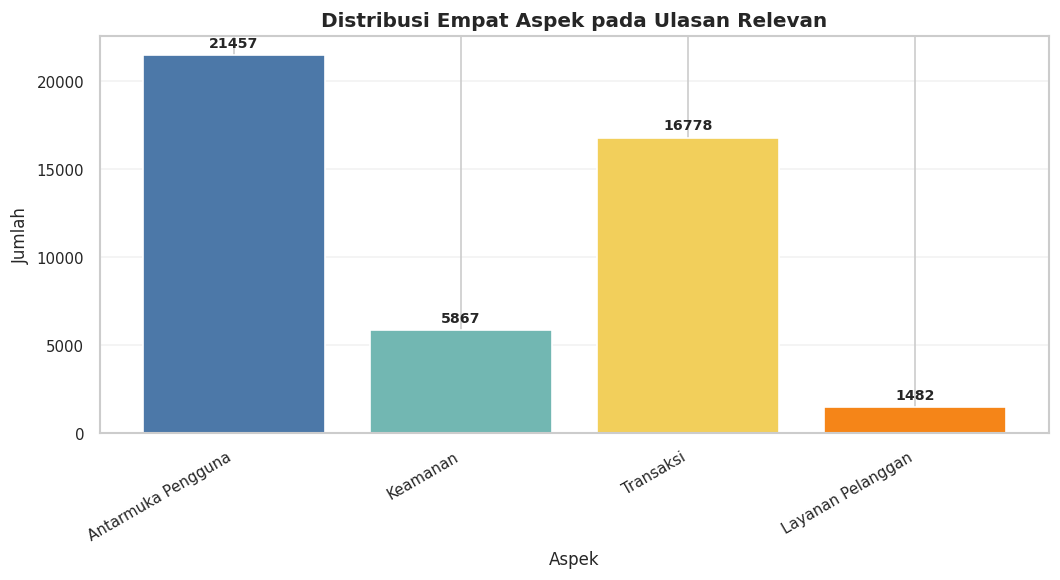

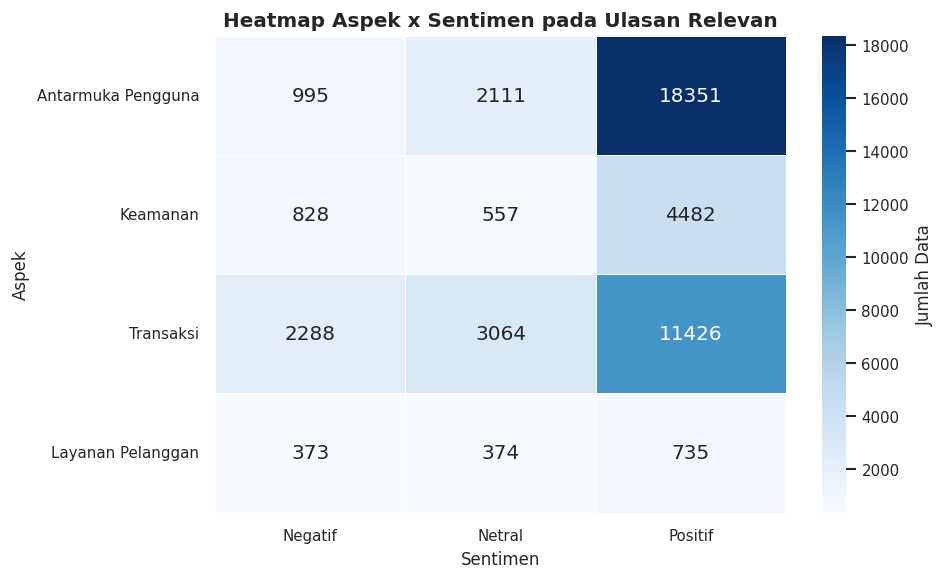

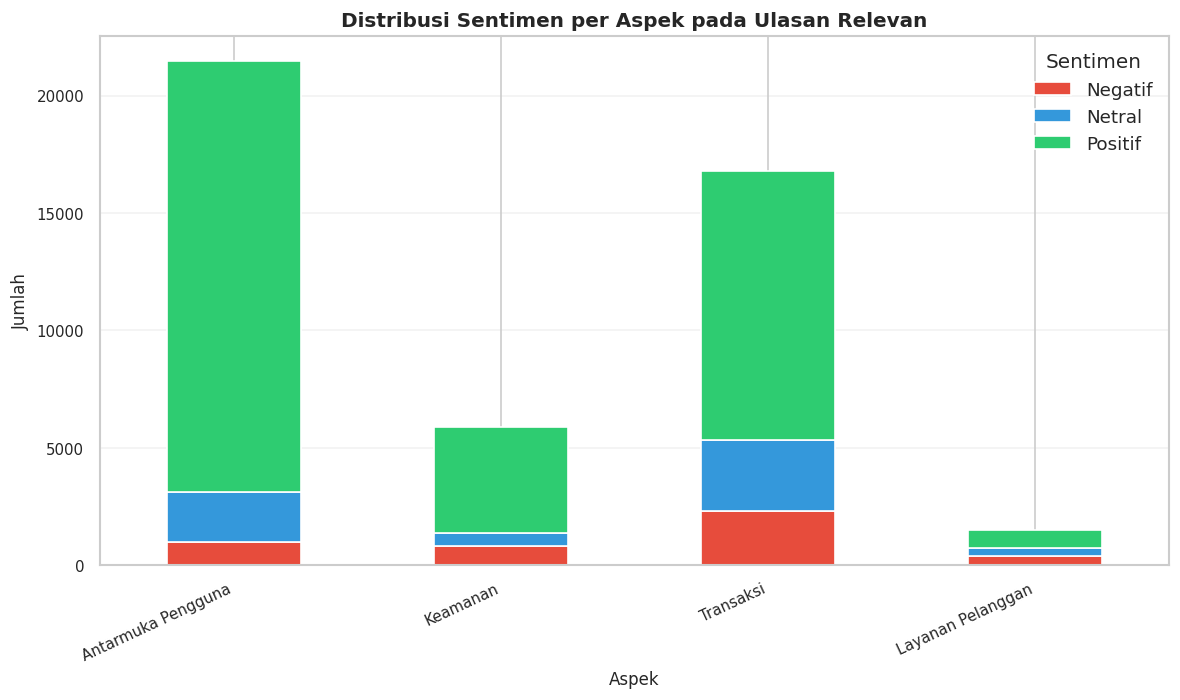

In [ ]:
# =========================================================
# 15. VISUALISASI HASIL ABSA — LABEL ANALISIS FINAL
# =========================================================

# Overview lima kelas relevance/aspect.
full_relevance_counts = (
    full_pred_df["analysis_aspect"]
    .value_counts()
    .reindex(ASPECT_MODEL_LABELS, fill_value=0)
)

# Analisis substantif hanya empat aspek relevan.
relevant_analysis_df = full_pred_df[
    full_pred_df["analysis_aspect"].isin(RESEARCH_ASPECT_LABELS)
    & full_pred_df["analysis_sentiment"].isin(SENTIMENT_LABELS)
].copy()

full_aspect_counts = (
    relevant_analysis_df["analysis_aspect"]
    .value_counts()
    .reindex(RESEARCH_ASPECT_LABELS, fill_value=0)
)
full_sent_counts = (
    relevant_analysis_df["analysis_sentiment"]
    .value_counts()
    .reindex(SENTIMENT_LABELS, fill_value=0)
)

plot_count_series(
    full_relevance_counts,
    "Distribusi Lima Kelas Model Aspek pada Seluruh Ulasan",
    "Kelas aspek/relevansi",
    "Jumlah",
    "11_full_distribusi_aspek_5class.png",
    colors=ASPECT_COLORS,
)
plot_count_series(
    full_aspect_counts,
    "Distribusi Empat Aspek pada Ulasan Relevan",
    "Aspek",
    "Jumlah",
    "11_full_distribusi_aspek_relevan.png",
    colors=ASPECT_COLORS,
)
plot_count_series(
    full_sent_counts,
    "Distribusi Sentimen pada Ulasan Relevan",
    "Sentimen",
    "Jumlah",
    "11_full_distribusi_sentimen_relevan.png",
    rotation=0,
    colors=SENTIMENT_COLORS,
)

full_crosstab = (
    pd.crosstab(
        relevant_analysis_df["analysis_aspect"],
        relevant_analysis_df["analysis_sentiment"],
    )
    .reindex(
        index=RESEARCH_ASPECT_LABELS,
        columns=SENTIMENT_LABELS,
        fill_value=0,
    )
)
display(full_crosstab)
save_df(
    full_crosstab.reset_index(),
    "11_full_crosstab_aspect_sentiment_relevant.xlsx",
)
plot_heatmap_table(
    full_crosstab,
    "Heatmap Aspek x Sentimen pada Ulasan Relevan",
    "11_full_heatmap_aspect_sentiment_relevant.png",
)

fig, axis = plt.subplots(figsize=(10, 6))
(
    full_crosstab.rename(
        index={
            value: pretty_label(value)
            for value in RESEARCH_ASPECT_LABELS
        },
        columns={
            value: pretty_label(value)
            for value in SENTIMENT_LABELS
        },
    )
    .plot(
        kind="bar",
        stacked=True,
        ax=axis,
        color=[
            SENTIMENT_COLORS["negatif"],
            SENTIMENT_COLORS["netral"],
            SENTIMENT_COLORS["positif"],
        ],
    )
)
axis.set_title("Distribusi Sentimen per Aspek pada Ulasan Relevan")
axis.set_xlabel("Aspek")
axis.set_ylabel("Jumlah")
axis.tick_params(axis="x", rotation=25)
for tick in axis.get_xticklabels():
    tick.set_ha("right")
axis.legend(title="Sentimen")
axis.grid(axis="y", alpha=0.25)
fig.tight_layout()
save_figure(
    fig,
    "11_full_stacked_sentiment_per_aspect_relevant.png",
)

if (
    "rating" in full_pred_df.columns
    and full_pred_df["rating"].notna().sum() > 0
):
    rating_counts = (
        full_pred_df["rating"]
        .value_counts()
        .sort_index()
    )
    save_df(
        rating_counts.rename_axis("rating").reset_index(name="jumlah"),
        "11_distribusi_rating_awal.xlsx",
    )
    plot_count_series(
        rating_counts,
        "Distribusi Rating Awal Seluruh Ulasan",
        "Rating awal",
        "Jumlah",
        "11_distribusi_rating_awal.png",
        rotation=0,
    )

    rating_sentiment_table = (
        pd.crosstab(
            relevant_analysis_df["rating"],
            relevant_analysis_df["analysis_sentiment"],
        )
        .reindex(columns=SENTIMENT_LABELS, fill_value=0)
    )
    save_df(
        rating_sentiment_table.reset_index(),
        "11_crosstab_rating_sentiment_relevant.xlsx",
    )


## 15. WordCloud reproducible pada data relevan

In [ ]:
# =========================================================
# 16. WORDCLOUD — REPRODUCIBLE DAN HANYA DATA RELEVAN
# =========================================================

STOPWORDS_ID = {
    "yang", "dan", "di", "ke", "dari", "untuk", "ini", "itu",
    "dengan", "saya", "aku", "nya", "the", "a", "an", "is",
    "indodax", "aplikasi", "crypto", "kripto",
}


def make_wordcloud(text_series, title, filename):
    text = " ".join(
        text_series.dropna().astype(str).tolist()
    )[:3_000_000]
    if not text.strip():
        print("WordCloud dilewati karena tidak ada teks:", title)
        return

    wordcloud = WordCloud(
        width=1200,
        height=700,
        background_color="white",
        stopwords=STOPWORDS_ID,
        max_words=120,
        collocations=False,
        random_state=SEED,
    ).generate(text)

    plt.figure(figsize=(12, 7))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(title)
    plt.tight_layout()
    path = FIG_DIR / filename
    plt.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight", facecolor="white")
    plt.show()
    print("Saved WordCloud:", path)


for sentiment in SENTIMENT_LABELS:
    subset = relevant_analysis_df[
        relevant_analysis_df["analysis_sentiment"] == sentiment
    ]
    make_wordcloud(
        subset["review_clean"],
        f"Wordcloud Sentimen {sentiment}",
        f"12_wordcloud_sentimen_{sentiment}.png",
    )

for aspect in RESEARCH_ASPECT_LABELS:
    subset = relevant_analysis_df[
        relevant_analysis_df["analysis_aspect"] == aspect
    ]
    make_wordcloud(
        subset["review_clean"],
        f"Wordcloud Aspek {aspect}",
        f"12_wordcloud_aspek_{aspect}.png",
    )

for aspect in RESEARCH_ASPECT_LABELS:
    subset = relevant_analysis_df[
        (relevant_analysis_df["analysis_aspect"] == aspect)
        & (relevant_analysis_df["analysis_sentiment"] == "negatif")
    ]
    make_wordcloud(
        subset["review_clean"],
        f"Wordcloud Negatif Aspek {aspect}",
        f"12_wordcloud_negatif_{aspect}.png",
    )


## 16. Paket Output BAB IV V5.4.2

In [ ]:
# =========================================================
# 16. PAKET OUTPUT BAB IV — V5.4.3 FINAL ROBUST FINGERPRINT FELIA STYLE
# =========================================================

BAB4_DIR = OUT_DIR / "bab4_ready"
BAB4_TABLE_DIR = BAB4_DIR / "tables"
BAB4_FIG_DIR = BAB4_DIR / "figures"
for directory in [BAB4_DIR, BAB4_TABLE_DIR, BAB4_FIG_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

ASPECT_SHORT = {
    "antarmuka_pengguna": "Antarmuka",
    "keamanan": "Keamanan",
    "transaksi": "Transaksi",
    "layanan_pelanggan": "Layanan pelanggan",
    "tidak_relevan": "Tidak relevan",
}
SENTIMENT_SHORT = {
    "negatif": "Negatif",
    "netral": "Netral",
    "positif": "Positif",
}


def save_bab4_table(dataframe, filename, index=False):
    path = BAB4_TABLE_DIR / filename
    dataframe.to_excel(path, index=index)
    print("Saved BAB IV table:", path)
    return path


def save_bab4_figure(fig, filename):
    path = BAB4_FIG_DIR / filename
    fig.tight_layout()
    fig.savefig(
        path,
        dpi=FIGURE_DPI,
        bbox_inches="tight",
        facecolor="white",
    )
    plt.show()
    plt.close(fig)
    print("Saved BAB IV figure:", path)
    return path


def compact_report(report_df, label_order=None):
    output = report_df.copy()
    if "label" not in output.columns:
        output = (
            output.reset_index()
            .rename(columns={"index": "label"})
        )

    keep_columns = [
        column
        for column in [
            "label",
            "precision",
            "recall",
            "f1-score",
            "support",
        ]
        if column in output.columns
    ]
    output = output[keep_columns].copy()

    if label_order is not None:
        summary_rows = ["accuracy", "macro avg", "weighted avg"]
        ordered_labels = [
            label
            for label in label_order
            if label in set(output["label"])
        ] + [
            label
            for label in summary_rows
            if label in set(output["label"])
        ]
        output["_order"] = pd.Categorical(
            output["label"],
            categories=ordered_labels,
            ordered=True,
        )
        output = (
            output.sort_values("_order")
            .drop(columns="_order")
        )

    for column in ["precision", "recall", "f1-score"]:
        if column in output.columns:
            output[column] = pd.to_numeric(
                output[column],
                errors="coerce",
            ).round(4)

    if "support" in output.columns:
        output["support"] = pd.to_numeric(
            output["support"],
            errors="coerce",
        ).round(0)

    return output.reset_index(drop=True)


def style_matplotlib_table(table_artist):
    for (row, column), cell in table_artist.get_celld().items():
        if row == 0:
            cell.set_text_props(weight="bold", color="white")
            cell.set_facecolor(FELIA_HEADER_BLUE)
        elif row % 2 == 0:
            cell.set_facecolor(FELIA_LIGHT_BLUE)
        else:
            cell.set_facecolor("white")


def plot_cm_with_report(
    y_true,
    y_pred,
    labels,
    title,
    filename,
    display_labels=None,
):
    matrix = confusion_matrix(
        y_true,
        y_pred,
        labels=labels,
    )
    report = pd.DataFrame(
        classification_report(
            y_true,
            y_pred,
            labels=labels,
            zero_division=0,
            output_dict=True,
        )
    ).T.reset_index().rename(columns={"index": "label"})
    report_compact = compact_report(report, labels)

    shown_labels = (
        display_labels
        if display_labels is not None
        else [pretty_label(label) for label in labels]
    )

    label_count = len(labels)
    if label_count <= 5:
        figure_size = (14, 5.8)
        rotation = 25
        annotation_size = 9
    else:
        figure_size = (20, 8.5)
        rotation = 55
        annotation_size = 6

    fig, axes = plt.subplots(
        1,
        2,
        figsize=figure_size,
        gridspec_kw={"width_ratios": [1.05, 1.25]},
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap=FELIA_BLUE_CMAP,
        linewidths=0.5,
        linecolor="white",
        square=label_count <= 5,
        cbar=True,
        annot_kws={"fontsize": annotation_size},
        ax=axes[0],
    )
    axes[0].set_title("Confusion Matrix")
    axes[0].set_xlabel("Label Prediksi")
    axes[0].set_ylabel("Label Aktual")
    axes[0].set_xticklabels(
        shown_labels,
        rotation=rotation,
        ha="right",
    )
    axes[0].set_yticklabels(
        shown_labels,
        rotation=0,
    )

    axes[1].axis("off")
    axes[1].set_title("Classification Report")

    report_table = report_compact.copy()
    report_table["label"] = report_table["label"].replace(
        dict(zip(labels, shown_labels))
    )
    report_table["label"] = report_table["label"].replace({
        "accuracy": "Accuracy",
        "macro avg": "Macro Average",
        "weighted avg": "Weighted Average",
    })

    table_values = []
    for _, row in report_table.iterrows():
        table_values.append([
            row.get("label", ""),
            (
                ""
                if pd.isna(row.get("precision"))
                else f'{row.get("precision"):.4f}'
            ),
            (
                ""
                if pd.isna(row.get("recall"))
                else f'{row.get("recall"):.4f}'
            ),
            (
                ""
                if pd.isna(row.get("f1-score"))
                else f'{row.get("f1-score"):.4f}'
            ),
            (
                ""
                if pd.isna(row.get("support"))
                else f'{int(row.get("support"))}'
            ),
        ])

    table_artist = axes[1].table(
        cellText=table_values,
        colLabels=[
            "Kelas",
            "Precision",
            "Recall",
            "F1-Score",
            "Support",
        ],
        cellLoc="center",
        colLoc="center",
        loc="center",
        colWidths=[0.30, 0.17, 0.17, 0.17, 0.16],
    )
    table_artist.auto_set_font_size(False)
    table_artist.set_fontsize(8.5 if label_count <= 5 else 6.5)
    table_artist.scale(1.0, 1.45 if label_count <= 5 else 1.2)
    style_matplotlib_table(table_artist)

    fig.suptitle(title, fontsize=14, fontweight="bold", y=1.02)
    save_bab4_figure(fig, filename)
    return report_compact, matrix


def plot_training_dashboard(history_df, title, filename):
    if history_df.empty:
        return None

    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    panels = [
        ("train_loss", "val_loss", "Loss"),
        ("train_acc", "val_acc", "Accuracy"),
        ("train_macro_f1", "val_macro_f1", "Macro F1"),
    ]

    for axis, (
        train_column,
        validation_column,
        label,
    ) in zip(axes, panels):
        axis.plot(
            history_df["epoch"],
            history_df[train_column],
            marker="o",
            label="Training",
        )
        axis.plot(
            history_df["epoch"],
            history_df[validation_column],
            marker="o",
            label="Validation",
        )
        axis.set_title(label)
        axis.set_xlabel("Epoch")
        axis.set_ylabel(label)
        axis.grid(alpha=0.25)
        axis.legend()

        if label in {"Accuracy", "Macro F1"}:
            axis.set_ylim(0, 1.05)

    fig.suptitle(title, fontsize=14, fontweight="bold")
    return save_bab4_figure(fig, filename)


def plot_tuning_comparison(tuning_df, title, filename):
    data = tuning_df.copy().sort_values("lstm_layers")
    fig, axis = plt.subplots(figsize=(9, 5))
    labels = [
        f"{int(value)} Layer"
        for value in data["lstm_layers"]
    ]
    axis.bar(
        labels,
        data["val_macro_f1"],
        color=FELIA_BAR_BLUE,
    )
    axis.set_title(title)
    axis.set_xlabel("Jumlah Layer BiLSTM")
    axis.set_ylabel("Validation Macro F1")
    axis.set_ylim(0, 1.05)
    axis.grid(axis="y", alpha=0.25)
    add_bar_value_labels(axis, decimals=4)
    return save_bab4_figure(fig, filename)


# ---------------------------------------------------------
# FASE 1 — DATA, PREPROCESSING, PELABELAN
# ---------------------------------------------------------
raw_columns = [
    column for column in [
        "id", "review_raw", "rating", "date", "user"
    ]
    if column in work_df.columns
]
save_bab4_table(
    work_df[raw_columns].head(10).copy(),
    "Tabel_4_1_Dataset_Hasil_Crawling.xlsx",
)

preprocessing_counts = pd.DataFrame([
    {
        "kondisi": "Data sebelum preprocessing",
        "jumlah": int(len(work_df)),
    },
    {
        "kondisi": "Data setelah preprocessing",
        "jumlah": int(len(clean_df)),
    },
    {
        "kondisi": "Data dihapus",
        "jumlah": int(len(work_df) - len(clean_df)),
    },
])
save_bab4_table(
    preprocessing_counts,
    "Tabel_4_2_Ringkasan_Preprocessing.xlsx",
)

label_quality_path = (
    BAB4_TABLE_DIR
    / "Tabel_4_3_Kualitas_Pelabelan_dan_Fleiss_Kappa.xlsx"
)
with pd.ExcelWriter(
    label_quality_path,
    engine="xlsxwriter",
) as writer:
    kappa_df.to_excel(
        writer,
        index=False,
        sheet_name="fleiss_kappa",
    )
    labeling_quality_df.to_excel(
        writer,
        index=False,
        sheet_name="quality_summary",
    )
    joint_table.reset_index().to_excel(
        writer,
        index=False,
        sheet_name="relevant_joint_distribution",
    )
    (
        labeled_df["aspect"]
        .value_counts()
        .reindex(ASPECT_MODEL_LABELS, fill_value=0)
        .rename_axis("aspect")
        .reset_index(name="count")
        .to_excel(
            writer,
            index=False,
            sheet_name="aspect_5class_distribution",
        )
    )
print("Saved BAB IV table:", label_quality_path)

fig, axis = plt.subplots(figsize=(10, 6))
(
    joint_table.rename(
        index=ASPECT_SHORT,
        columns=SENTIMENT_SHORT,
    )
    .plot(
        kind="bar",
        ax=axis,
        color=[
            SENTIMENT_COLORS["negatif"],
            SENTIMENT_COLORS["netral"],
            SENTIMENT_COLORS["positif"],
        ],
    )
)
axis.set_title(
    "Distribusi Label Relevan Berdasarkan Aspek dan Sentimen"
)
axis.set_xlabel("Aspek")
axis.set_ylabel("Jumlah data")
axis.tick_params(axis="x", rotation=20)
axis.legend(title="Sentimen")
axis.grid(axis="y", alpha=0.25)
add_bar_value_labels(axis)
save_bab4_figure(
    fig,
    "Gambar_4_1_Distribusi_Label_Relevan.png",
)

# ---------------------------------------------------------
# FASE 2 — GROUP SPLIT, ROS, TRAINING
# ---------------------------------------------------------
split_method_path = (
    BAB4_TABLE_DIR
    / "Tabel_4_4_Group_Split_dan_Near_Duplicate_Audit.xlsx"
)
with pd.ExcelWriter(
    split_method_path,
    engine="xlsxwriter",
) as writer:
    split_info.to_excel(
        writer,
        index=False,
        sheet_name="split_distribution",
    )
    near_duplicate_group_audit_df.to_excel(
        writer,
        index=False,
        sheet_name="near_duplicate_groups",
    )
    group_split_overlap_audit_df.to_excel(
        writer,
        index=False,
        sheet_name="group_overlap_audit",
    )
print("Saved BAB IV table:", split_method_path)

balancing_path = (
    BAB4_TABLE_DIR
    / "Tabel_4_5_Random_Oversampling_Train.xlsx"
)
with pd.ExcelWriter(
    balancing_path,
    engine="xlsxwriter",
) as writer:
    aspect_balance_table.to_excel(
        writer,
        index=False,
        sheet_name="aspect_model",
    )
    sentiment_joint_balance_table.to_excel(
        writer,
        index=False,
        sheet_name="sentiment_joint",
    )
    balance_info.to_excel(
        writer,
        index=False,
        sheet_name="detail",
    )
print("Saved BAB IV table:", balancing_path)

plot_data = aspect_balance_table.set_index(
    "aspect"
)[["before", "after"]]
fig, axis = plt.subplots(figsize=(10, 5))
plot_data.rename(
    index={
        value: pretty_label(value)
        for value in plot_data.index
    },
    columns={
        "before": "Sebelum ROS",
        "after": "Sesudah ROS",
    },
).plot(
    kind="bar",
    ax=axis,
    color=[FELIA_BAR_BLUE_LIGHT, FELIA_BAR_BLUE],
)
axis.set_title(
    "Model Aspek: Sebelum dan Sesudah Random Oversampling"
)
axis.set_xlabel("Kelas model aspek")
axis.set_ylabel("Jumlah data")
axis.tick_params(axis="x", rotation=25)
for tick in axis.get_xticklabels():
    tick.set_ha("right")
axis.grid(axis="y", alpha=0.25)
add_bar_value_labels(axis)
save_bab4_figure(
    fig,
    "Gambar_4_2_ROS_Model_Aspek.png",
)

save_bab4_table(
    aspect_tuning_results.sort_values("lstm_layers"),
    "Tabel_4_6_Eksperimen_Model_Aspek.xlsx",
)
save_bab4_table(
    sentiment_tuning_results.sort_values("lstm_layers"),
    "Tabel_4_7_Eksperimen_Model_Sentimen.xlsx",
)

plot_tuning_comparison(
    aspect_tuning_results,
    "Perbandingan BiLSTM Model Aspek",
    "Gambar_4_3_Tuning_Model_Aspek.png",
)
plot_training_dashboard(
    best_aspect_history,
    "Training Model Aspek Terbaik",
    "Gambar_4_4_Training_Model_Aspek.png",
)
plot_tuning_comparison(
    sentiment_tuning_results,
    "Perbandingan BiLSTM Model Sentimen",
    "Gambar_4_5_Tuning_Model_Sentimen.png",
)
plot_training_dashboard(
    best_sentiment_history,
    "Training Model Sentimen Terbaik",
    "Gambar_4_6_Training_Model_Sentimen.png",
)

# ---------------------------------------------------------
# FASE 3 — EVALUASI
# ---------------------------------------------------------
save_bab4_table(
    metrics_summary,
    "Tabel_4_8_Ringkasan_Evaluasi_Model.xlsx",
)
save_bab4_table(
    per_aspect_eval_df,
    "Tabel_4_9_Evaluasi_per_Aspek.xlsx",
)

aspect_report_bab4, _ = plot_cm_with_report(
    test_eval_df["aspect"],
    test_eval_df["pred_aspect"],
    ASPECT_MODEL_LABELS,
    "Evaluasi Model Aspek Lima Kelas",
    "Gambar_4_7_CM_dan_Report_Aspek_5Kelas.png",
    [ASPECT_SHORT[label] for label in ASPECT_MODEL_LABELS],
)
save_bab4_table(
    aspect_report_bab4,
    "Tabel_4_10_Classification_Report_Aspek_5Kelas.xlsx",
)

if pipeline_eval_df.empty:
    sentiment_report_bab4 = sentiment_pipeline_report_df.copy()
    save_bab4_table(
        sentiment_report_bab4,
        "Tabel_4_11_Classification_Report_Sentimen_Pipeline.xlsx",
    )
    print(
        "Gambar sentimen pipeline dilewati karena pipeline coverage = 0."
    )
else:
    sentiment_report_bab4, _ = plot_cm_with_report(
        pipeline_eval_df["sentiment"],
        pipeline_eval_df["pred_sentiment_pipeline"],
        SENTIMENT_LABELS,
        "Evaluasi Sentimen Pipeline Kondisional",
        "Gambar_4_8_CM_dan_Report_Sentimen_Pipeline.png",
        [SENTIMENT_SHORT[label] for label in SENTIMENT_LABELS],
    )
    save_bab4_table(
        sentiment_report_bab4,
        "Tabel_4_11_Classification_Report_Sentimen_Pipeline.xlsx",
    )

save_bab4_table(
    compact_report(joint_report_df, JOINT_LABELS),
    "Tabel_4_12_Classification_Report_Joint_ABSA_13Kelas.xlsx",
)

# ---------------------------------------------------------
# FASE 4 — ANALISIS KORPUS
# ---------------------------------------------------------
relevance_distribution_df = (
    full_relevance_counts
    .rename_axis("aspect_or_relevance")
    .reset_index(name="count")
)
relevant_aspect_distribution_df = (
    full_aspect_counts
    .rename_axis("aspect")
    .reset_index(name="count")
)
relevant_sentiment_distribution_df = (
    full_sent_counts
    .rename_axis("sentiment")
    .reset_index(name="count")
)

save_bab4_table(
    relevance_distribution_df,
    "Tabel_4_13_Distribusi_5Kelas_Aspek_Relevansi.xlsx",
)
save_bab4_table(
    relevant_aspect_distribution_df,
    "Tabel_4_14_Distribusi_4Aspek_Relevan.xlsx",
)
save_bab4_table(
    relevant_sentiment_distribution_df,
    "Tabel_4_15_Distribusi_Sentimen_Relevan.xlsx",
)
save_bab4_table(
    full_crosstab.reset_index(),
    "Tabel_4_16_Distribusi_Aspek_dan_Sentimen_Relevan.xlsx",
)

example_columns = [
    column for column in [
        "id",
        "review_raw",
        "review_clean",
        "rating",
        "analysis_aspect",
        "analysis_sentiment",
        "label_source",
        "pred_aspect",
        "aspect_confidence",
        "pred_sentiment",
        "sentiment_confidence",
    ]
    if column in full_pred_df.columns
]
prediction_examples = (
    relevant_analysis_df
    .sort_values(
        [
            "analysis_aspect",
            "analysis_sentiment",
            "analysis_aspect_confidence",
        ],
        ascending=[True, True, False],
    )
    .groupby(
        ["analysis_aspect", "analysis_sentiment"],
        group_keys=False,
    )
    .head(2)[example_columns]
    .reset_index(drop=True)
)
save_bab4_table(
    prediction_examples,
    "Tabel_4_17_Contoh_Hasil_Analisis.xlsx",
)

fig, axis = plt.subplots(figsize=(9, 5))
axis.bar(
    [
        ASPECT_SHORT[label]
        for label in RESEARCH_ASPECT_LABELS
    ],
    relevant_aspect_distribution_df["count"],
    color=[
        ASPECT_COLORS[label]
        for label in RESEARCH_ASPECT_LABELS
    ],
)
axis.set_title("Distribusi Empat Aspek pada Ulasan Relevan")
axis.set_xlabel("Aspek")
axis.set_ylabel("Jumlah ulasan")
axis.tick_params(axis="x", rotation=20)
axis.grid(axis="y", alpha=0.25)
add_bar_value_labels(axis)
save_bab4_figure(
    fig,
    "Gambar_4_9_Distribusi_4Aspek_Relevan.png",
)

fig, axis = plt.subplots(figsize=(8, 5))
axis.bar(
    [
        SENTIMENT_SHORT[label]
        for label in SENTIMENT_LABELS
    ],
    relevant_sentiment_distribution_df["count"],
    color=[
        SENTIMENT_COLORS[label]
        for label in SENTIMENT_LABELS
    ],
)
axis.set_title("Distribusi Sentimen pada Ulasan Relevan")
axis.set_xlabel("Sentimen")
axis.set_ylabel("Jumlah ulasan")
axis.grid(axis="y", alpha=0.25)
add_bar_value_labels(axis)
save_bab4_figure(
    fig,
    "Gambar_4_10_Distribusi_Sentimen_Relevan.png",
)

fig, axis = plt.subplots(figsize=(10, 6))
(
    full_crosstab.rename(
        index=ASPECT_SHORT,
        columns=SENTIMENT_SHORT,
    )
    .plot(
        kind="bar",
        stacked=True,
        ax=axis,
        color=[
            SENTIMENT_COLORS["negatif"],
            SENTIMENT_COLORS["netral"],
            SENTIMENT_COLORS["positif"],
        ],
    )
)
axis.set_title("Distribusi Sentimen pada Setiap Aspek")
axis.set_xlabel("Aspek")
axis.set_ylabel("Jumlah ulasan")
axis.tick_params(axis="x", rotation=20)
axis.legend(title="Sentimen")
axis.grid(axis="y", alpha=0.25)
save_bab4_figure(
    fig,
    "Gambar_4_11_Sentimen_per_Aspek.png",
)

manifest_rows = [
    (
        "Tabel 4.1",
        "Hasil crawling",
        "tables/Tabel_4_1_Dataset_Hasil_Crawling.xlsx",
    ),
    (
        "Tabel 4.2",
        "Hasil preprocessing",
        "tables/Tabel_4_2_Ringkasan_Preprocessing.xlsx",
    ),
    (
        "Tabel 4.3",
        "Pelabelan dan Fleiss' Kappa",
        "tables/Tabel_4_3_Kualitas_Pelabelan_dan_Fleiss_Kappa.xlsx",
    ),
    (
        "Tabel 4.4",
        "Near-duplicate group split",
        "tables/Tabel_4_4_Group_Split_dan_Near_Duplicate_Audit.xlsx",
    ),
    (
        "Tabel 4.5",
        "Random Oversampling",
        "tables/Tabel_4_5_Random_Oversampling_Train.xlsx",
    ),
    (
        "Tabel 4.8",
        "Evaluasi model",
        "tables/Tabel_4_8_Ringkasan_Evaluasi_Model.xlsx",
    ),
    (
        "Tabel 4.13–4.16",
        "Analisis korpus",
        "tables/",
    ),
]
manifest_df = pd.DataFrame(
    manifest_rows,
    columns=[
        "nomor",
        "subbab",
        "lokasi_output",
    ],
)
save_bab4_table(
    manifest_df,
    "MANIFEST_OUTPUT_BAB4.xlsx",
)

with open(
    BAB4_DIR / "PANDUAN_OUTPUT_BAB4.txt",
    "w",
    encoding="utf-8",
) as file:
    file.write(
        "Output V5.4.1 menggunakan model aspek lima kelas dan visual Felia Style. "
        "Kelas tidak_relevan berfungsi sebagai relevance gate. "
        "Analisis sentimen dan empat aspek hanya memakai ulasan relevan. "
        "Split menggunakan near-duplicate group agar ulasan mirip tidak "
        "tersebar antara train, validation, dan test.\n"
    )

print("Paket BAB IV tersimpan di:", BAB4_DIR)


## 17. Export hasil akhir

In [ ]:
# =========================================================
# 17. EXPORT HASIL AKHIR — V5.4 METODOLOGI
# =========================================================

full_relevance_counts_df = (
    full_relevance_counts
    .rename_axis("aspect_or_relevance")
    .reset_index(name="count")
)
full_aspect_counts_df = (
    full_aspect_counts
    .rename_axis("aspect")
    .reset_index(name="count")
)
full_sentiment_counts_df = (
    full_sent_counts
    .rename_axis("sentiment")
    .reset_index(name="count")
)
full_crosstab_df = full_crosstab.reset_index()

analysis_tables = {
    "relevance_5class_counts": full_relevance_counts_df,
    "relevant_aspect_counts": full_aspect_counts_df,
    "relevant_sentiment_counts": full_sentiment_counts_df,
    "relevant_aspect_sentiment": full_crosstab_df,
    "metrics_summary": metrics_summary,
    "per_aspect_evaluation": per_aspect_eval_df,
    "aspect_tuning_results": aspect_tuning_results,
    "sentiment_tuning_results": sentiment_tuning_results,
    "split_info": split_info,
    "oversampling_info": balance_info,
    "near_duplicate_group_audit": near_duplicate_group_audit_df,
    "group_split_overlap_audit": group_split_overlap_audit_df,
    "joint_classification_report": joint_report_df,
    "joint_test_support": joint_support_df,
    "per_aspect_test_support": per_aspect_sentiment_support_df,
    "full_prediction_source_audit": full_prediction_audit_df,
}

with pd.ExcelWriter(
    OUT_DIR / "12_analysis_tables.xlsx",
    engine="xlsxwriter",
) as writer:
    for sheet_name, dataframe in analysis_tables.items():
        dataframe.to_excel(
            writer,
            index=False,
            sheet_name=sheet_name[:31],
        )

print(
    "Analysis tables tersimpan:",
    OUT_DIR / "12_analysis_tables.xlsx",
)

readme = f"""
NOTEBOOK ABSA INDODAX — V5.4.3 FINAL ROBUST FINGERPRINT FELIA STYLE
Generated at: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}

PERUBAHAN UTAMA:
1. Model aspek menggunakan lima kelas, termasuk tidak_relevan sebagai relevance gate.
2. Empat aspek penelitian tetap: antarmuka pengguna, keamanan, transaksi, dan layanan pelanggan.
3. Model sentimen hanya dilatih dan dievaluasi pada ulasan relevan.
4. Joint ABSA dievaluasi sebagai 13 kelas: tidak_relevan + 12 kombinasi aspek-sentimen.
5. Split memakai StratifiedGroupKFold dan near-duplicate grouping berbasis TF-IDF karakter.
6. Random Oversampling hanya pada training set dan dibuat terpisah untuk model aspek serta sentimen.
7. BiLSTM menggunakan pack_padded_sequence agar padding tidak diproses sebagai token valid.
8. Early stopping memakai validation macro F1.
9. Istilah domain login, fee, withdraw, deposit, OTP, KYC, wallet, dan spread dipertahankan.
10. Prediksi korpus menggunakan label Majority Voting pada data yang sudah berlabel, sedangkan model dipakai pada data belum berlabel.
11. WordCloud memakai random_state=SEED.
12. Versi library dan provenance anotasi disimpan.

ANNOTATION PROVENANCE:
{json.dumps(annotation_provenance_info, ensure_ascii=False, indent=2)}

CATATAN AKADEMIK:
Notebook final ini memakai hard guard: provenance wajib manual_human dan final_research_run=true.
Fase 4 tidak akan melanjutkan bila lineage Fase 2/Fase 3 tidak memenuhi syarat tersebut.
"""

with open(
    OUT_DIR / "README_HASIL.txt",
    "w",
    encoding="utf-8",
) as file:
    file.write(readme)

with open(
    OUT_DIR / "00_library_versions.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        library_versions,
        file,
        indent=2,
        ensure_ascii=False,
    )

print("Export tabel dan README selesai. ZIP terverifikasi dibuat pada cell terakhir.")


## 18. Sanity check output dan assertion metodologis

In [ ]:
# =========================================================
# 18. SANITY CHECK OUTPUT FINAL — V5.4.3
# =========================================================

required_output_files = [
    OUT_DIR / "00_input_preflight.xlsx",
    OUT_DIR / "00_model_load_audit.xlsx",
    OUT_DIR / "00_pipeline_fingerprint.json",
    OUT_DIR / "00_source_lineage.json",
    OUT_DIR / "11_full_prediction_metadata.json",
    OUT_DIR / "bab4_ready" / "tables" / "MANIFEST_OUTPUT_BAB4.xlsx",
    OUT_DIR / "bab4_ready" / "PANDUAN_OUTPUT_BAB4.txt",
    OUT_DIR / "00_run_config.json",
    OUT_DIR / "00_library_versions.json",
    OUT_DIR / "06_final_majority_labels.xlsx",
    OUT_DIR / "06_fleiss_kappa.xlsx",
    OUT_DIR / "07_train_aspect_oversampled.xlsx",
    OUT_DIR / "07_train_sentiment_oversampled.xlsx",
    OUT_DIR / "07_validation.xlsx",
    OUT_DIR / "07_test.xlsx",
    OUT_DIR / "07_near_duplicate_group_audit.xlsx",
    OUT_DIR / "07_group_split_overlap_audit.xlsx",
    OUT_DIR / "08_aspect_tuning_results.xlsx",
    OUT_DIR / "09_sentiment_tuning_results.xlsx",
    OUT_DIR / "10_metrics_summary.xlsx",
    OUT_DIR / "10_classification_report_aspect_5class.xlsx",
    OUT_DIR / "10_classification_report_sentiment_gold_aspect.xlsx",
    OUT_DIR / "10_classification_report_sentiment_pipeline_conditional.xlsx",
    OUT_DIR / "10_classification_report_joint_absa_13class.xlsx",
    OUT_DIR / "10_joint_label_test_support_audit.xlsx",
    OUT_DIR / "10_per_aspect_sentiment_test_support_audit.xlsx",
    OUT_DIR / "10_test_size_audit.xlsx",
    OUT_DIR / "10_test_predictions_detail.xlsx",
    OUT_DIR / "11_full_prediction_results.xlsx",
    OUT_DIR / "11_full_prediction_source_audit.xlsx",
    OUT_DIR / "12_analysis_tables.xlsx",
]

sanity_rows = []
for path in required_output_files:
    sanity_rows.append({
        "path": str(path),
        "status": "exists" if path.exists() else "missing",
    })

sanity_check_df = pd.DataFrame(sanity_rows)
display(sanity_check_df)

missing_files = sanity_check_df[
    sanity_check_df["status"] == "missing"
]["path"].tolist()

methodology_assertions = pd.DataFrame([
    {
        "check": "final_manual_human_lineage",
        "passed": (
            annotation_provenance_info.get("annotation_provenance") == "manual_human"
            and annotation_provenance_info.get("final_research_run") is True
            and stage3_run_config.get("annotation_provenance") == "manual_human"
            and stage3_run_config.get("final_research_run") is True
            and stage3_run_config.get("pipeline_version") == REQUIRED_STAGE3_PIPELINE
        ),
    },
    {
        "check": "aspect_model_has_irrelevant_class",
        "passed": IRRELEVANT_ASPECT_LABEL in ASPECT_MODEL_LABELS,
    },
    {
        "check": "sentiment_training_excludes_irrelevant",
        "passed": not (
            train_sentiment_df["aspect"]
            == IRRELEVANT_ASPECT_LABEL
        ).any(),
    },
    {
        "check": "group_split_no_overlap",
        "passed": int(
            group_split_overlap_audit_df[
                "overlap_group_count"
            ].sum()
        ) == 0,
    },
    {
        "check": "joint_has_13_classes",
        "passed": len(JOINT_LABELS) == 13,
    },
    {
        "check": "human_labels_used_when_available",
        "passed": (
            full_pred_df.loc[
                full_pred_df["human_aspect"].notna(),
                "label_source",
            ]
            == "majority_voting"
        ).all(),
    },
    {
        "check": "packed_bilstm_available",
        "passed": hasattr(aspect_model, "run_bilstm"),
    },
])
display(methodology_assertions)
save_df(
    methodology_assertions,
    "18_methodology_assertion_audit.xlsx",
)

if missing_files:
    print(
        "Peringatan: output belum lengkap. File hilang:",
        missing_files,
    )
else:
    print("Semua file output utama sudah terbentuk.")

assert methodology_assertions["passed"].all(), (
    "Ada assertion metodologis yang gagal."
)


## Checkpoint dan paket akhir Fase 4

Seluruh prediksi korpus, tabel, gambar, audit metodologis, dan paket `bab4_ready` dikompresi menjadi satu ZIP.


In [ ]:
# =========================================================
# CHECKPOINT FASE 4 — MANIFEST DAN ZIP TERVERIFIKASI
# =========================================================

stage4_manifest_rows = []
for path in sorted(OUT_DIR.rglob("*")):
    if path.is_file():
        stage4_manifest_rows.append({
            "path": str(path.relative_to(OUT_DIR)),
            "size_bytes": int(path.stat().st_size),
            "size_mb": round(
                path.stat().st_size / (1024 ** 2),
                4,
            ),
        })

stage4_manifest = pd.DataFrame(stage4_manifest_rows)
stage4_manifest.to_excel(
    OUT_DIR / "STAGE4_MANIFEST.xlsx",
    index=False,
)


def create_verified_archive(
    source_dir,
    final_zip_path,
):
    final_zip_path = Path(final_zip_path)
    temporary_root = Path("/content") / (
        final_zip_path.stem + "_temporary"
    )
    temporary_zip = temporary_root.with_suffix(".zip")

    if temporary_zip.exists():
        temporary_zip.unlink()

    created_path = Path(
        shutil.make_archive(
            str(temporary_root),
            "zip",
            root_dir=source_dir,
        )
    )

    valid, reason = inspect_zip(created_path)
    if not valid:
        raise RuntimeError(
            f"ZIP output gagal verifikasi: {reason}"
        )

    final_zip_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )
    shutil.copy2(created_path, final_zip_path)

    copied_valid, copied_reason = inspect_zip(
        final_zip_path
    )
    if not copied_valid:
        raise RuntimeError(
            "ZIP telah dibuat tetapi salinan Google Drive "
            f"gagal verifikasi: {copied_reason}"
        )

    created_path.unlink(missing_ok=True)
    return final_zip_path


FINAL_STAGE4_ZIP = (
    PROJECT_DIR
    / "stage4_bab4_results_v5_4_3_final_robust_fingerprint.zip"
)

stage4_zip = create_verified_archive(
    source_dir=OUT_DIR,
    final_zip_path=FINAL_STAGE4_ZIP,
)

print("Paket akhir Fase 4:", stage4_zip)
print(
    "Ukuran ZIP:",
    round(stage4_zip.stat().st_size / (1024 ** 2), 2),
    "MB",
)
print("Valid ZIP:", zipfile.is_zipfile(stage4_zip))
print("Seluruh fase selesai.")
print(
    "Session terputus? Jalankan ulang notebook. "
    "Prediksi lengkap/cache chunk akan digunakan kembali."
)
